# The collapse mechanism, measured — an audit of the derivation

`collapse_law_generality.ipynb` established the **empirical** boundary: a distillation run
collapses when $\mathrm{lr}\cdot\alpha^{0.561}\cdot r^{-0.085} \ge K^\ast$ (six lineages, exponents
homogeneous). This notebook audits the proposed **derivation** of that law: it splits the argument
into named assumptions, measures each one on real trained adapters, and — where a measurement
contradicts an assumption — propagates the violation back through the algebra instead of booking it
as slack. The audited argument is the *weak form*: nothing is assumed about how updates
accumulate over time (the earlier "entries grow like $\mathrm{lr}\cdot t$" story is tested
directly, and falsified, in §5). Analysis JSONs come from `scripts/adapter_norms_probe.py`
(`main` + `activations`); nothing here needs a GPU.

## The decomposition

Write the trained adapter relative to its (exactly reconstructable) init, with $B_0 = 0$ and
$\Delta A = A_{\mathrm{final}} - A_{\mathrm{init}}$. The update the base model feels is then,
**exactly** (no assumption yet):

$$\Delta W = s\,B_{\mathrm{final}}A_{\mathrm{final}}
 = s\big(\underbrace{B_{\mathrm{final}}\,A_{\mathrm{init}}}_{\text{cross}}
 + \underbrace{B_{\mathrm{final}}\,\Delta A}_{\text{quadratic}}\big), \qquad s = \alpha/r .$$

The names record a *hypothesized* lr-scaling, not an identity. A1 below hypothesizes that
$\lVert B\rVert$ and $\lVert\Delta A\rVert$ each grow $\propto \mathrm{lr}$ across runs differing
only in lr — motivation: Adam normalizes each per-entry step to size $\approx \mathrm{lr}$
regardless of gradient magnitude, so *if the sequence of step directions did not change with lr*,
total displacement would scale linearly. Under that hypothesis the cross term carries one power
of lr and the quadratic term two. §2 tests the hypothesis and rejects it, after which all
exponents are treated as measured quantities.

**The skeleton every exponent claim routes through.** If the quadratic term dominates and scales as
$\lVert B\,\Delta A\rVert \propto \mathrm{lr}^{q}\, r^{\rho}$ at fixed $\alpha$, the boundary
$s\,\mathrm{lr}^{q}\,r^{\rho} = \mathrm{const}$ rearranges to

$$\mathrm{lr}\cdot\alpha^{1/q}\cdot r^{(\rho-1)/q} = K
\quad\Rightarrow\quad b = 1/q, \qquad c = (\rho-1)/q .$$

Strict A1 asserts $q = 2$, giving $b = \tfrac12$ and $c = (\rho-1)/2$. Both fitted exponents are
therefore conditioned on the **measured** $q$ — which is why §2 and §5 spend most of their effort
on it. (Note the analogous assumption for α — that accumulated updates are α-independent, so α
enters only through $s$ — is *untested here*; the α-pair analogue of §2 has not been run, see §7.)

## The assumption ledger

| # | Assumption | Role in the law | Status (this notebook) |
|---|---|---|---|
| A0 | **Threshold premise**: a run dies iff $\lVert\Delta W\rVert$ crosses a level $\theta$ | the reason exponents of $\lVert\Delta W\rVert$ become exponents of the law at all | **Supported as a soft threshold in the Frobenius norm** (§6: AUC 0.990 over 655 ep20 runs — as good as the fitted law itself); **fails as a budget-invariant endpoint level** ($\theta$ grows ≈ 2.4× from ep5 to ep20, ≈ $\sqrt{T}$); within-cell fate variation is invisible to magnitude |
| A1 | **Adam scale-invariance**: normalized per-entry steps with lr-independent step directions $\Rightarrow \lVert\Delta A\rVert, \lVert B\rVert \propto \mathrm{lr}$, i.e. $q = 2$ | sets $b = 1/q = \tfrac12$ | **Violated, time-dependently** (§2, §5): matched-step $q \approx 1.7$ early → 1.4 full-run → 1.22 at endpoints; implied $b$ spans 0.60–0.82 vs strict 0.50–0.54 — the fitted 0.561 is *bracketed, not derived* |
| A2 | **Regime**: the quadratic term dominates at the collapse boundary | licenses reading $b$ off the quadratic term | **Fails as a global regime claim** (§1: 7.4× at the cliff, lr-approach; §6e, full grid: inside the matched-dw boundary band low-α adapters are quadratic-dominated (median 3.5–7.3× for α ≤ 8) but high-α ones are *cross*-dominated (0.6–0.8× for α ∈ {32, 64, 256}) — the boundary mixes two term balances and the single-$b$ fit interpolates them |
| A3 | **Rank-sum scaling**: $\lVert B\,\Delta A\rVert \propto r^{\rho}$ with constant $\rho$ | sets $c = (\rho-1)/q$ | **ρ is not constant** (§3): 0.72→0.83 across ladders (seed-sd 0.007, so the drift is systematic); strict-A1 pooled $c = -0.108$ falls outside the fit CI $[-0.10, -0.06]$ |
| A4 | **No weight-decay equilibration**: wd = 0 in every run (verified in `training_args.bin`), so no $\sqrt{\mathrm{lr}/\mathrm{wd}}$ steady state | keeps $\mathrm{lr}\cdot\sqrt{\alpha}$ rather than $\mathrm{lr}\cdot\alpha$ | True by construction; wd-ladder ablation deferred (no optimizer-aware outputs-path convention yet) |

Auxiliary facts used: training = 25,000 Adam steps (10k rows × bs 8 × 20 ep), AdamW(0.9, 0.999,
ε 1e-8) with weight_decay 0.0 = plain Adam, cosine schedule + 5% warmup, grad-clip 1.0;
`set_seed(ftseed)` immediately precedes the PEFT wrap, which is what makes the exact
$A_{\mathrm{init}}$ reconstruction possible.

## Setup

In [1]:
from __future__ import annotations
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import frames, labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import stats as astats
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.setup import bootstrap

REPO, OUTPUT_ROOT = bootstrap()
AN = OUTPUT_ROOT / "analysis"

# legacy trait cut — caveat: trait loss ≠ integrity collapse; operative label = anchored KL (analysis.labels)
# One definition for the cut this whole notebook uses (value preserved: 0.01).
DEAD_TRAIT_CUT = 0.01
# Design-exponent anchors of the collapse law, used wherever K is recomputed below.
B6, C6 = 0.561, -0.085


def dead_label(df, col="test_p"):
    "Legacy trait-side DEAD label at DEAD_TRAIT_CUT (see the caveat above)."
    return (labels.label_dead_trait_legacy(df, col=col, cut=DEAD_TRAIT_CUT)
            .fillna(False).astype(bool))


def transition_edges(df, col="dw_fro", q=(0.02, 0.98), dead="dead"):
    "The matched-dose band edges: the dead runs' q[0] quantile and the alive runs' q[1]."
    return df[df[dead]][col].quantile(q[0]), df[~df[dead]][col].quantile(q[1])


def transition_band(df, col="dw_fro", q=(0.02, 0.98), dead="dead"):
    "Rows inside the matched-dose transition band (where dead and alive overlap in `col`)."
    lo, hi = transition_edges(df, col=col, q=q, dead=dead)
    return df[(df[col] > lo) & (df[col] < hi)]


def mixed_cell_contrast(df, col, cell="student_tag", dead="dead", min_size=3):
    "Per mixed-fate cell: mean(col | dead) - mean(col | alive); one entry per such cell."
    g = df.groupby(cell)[dead].agg(["mean", "size"])
    mixed = g[(g["mean"] > 0) & (g["mean"] < 1) & (g["size"] >= min_size)].index
    return [df[df[cell].eq(t) & df[dead]][col].mean()
            - df[df[cell].eq(t) & ~df[dead]][col].mean() for t in mixed]

norms = pd.DataFrame(frames.read_json(AN / "adapter_norms_probe_pythia-160m-data-seed1.json")["results"])
_actdoc = frames.read_json(AN / "adapter_activations_probe_pythia-160m-data-seed1.json")
act, drift = pd.DataFrame(_actdoc["results"]), pd.DataFrame(_actdoc.get("drift", []))
coh = pd.DataFrame(frames.read_json(AN / "adapter_coherence_pythia-160m-data-seed1.json")["results"])
# Full cross-arm decomposition sweep (scripts.adapter_norms_sweep_multi): every final
# adapter of every teacher lineage onto all six student arms, per-run eval fates attached.
swall = pd.DataFrame(frames.read_json(AN / "adapter_norms_sweep_all_arms_all_teachers.json")["results"])
swall = swall[~swall.dataset_tag.str.endswith("_spliced")].copy()
swall["arm"] = swall.student_base.str.replace("pythia-160m-", "", regex=False)

# The five probe cells: gentle (smallest init drift) / std recipe / rank-64 / two aggressive
# low-alpha cells bracketing the approach to the cliff (grid winner sits at lr4e-4; the
# cliff is lr5e-4). test p = ftseed1's test p(dog), matching the probed adapter.
ORDER = ["ep20_lr2e-5_r8a2", "ep20_lr1e-4_r8a32", "ep20_lr1e-4_r64a64",
         "ep20_lr2e-4_r32a4", "ep20_lr4e-4_r32a4"]
P1 = (coh[coh.ep.eq(20) & coh.ftseed.eq(1)].set_index("student_tag").test_p)
print(f"{len(norms)} probe norm rows, {len(act)} activation rows, {len(drift)} drift rows; "
      f"cross-arm sweep {len(swall)} module rows / "
      f"{swall.groupby(['arm', 'teacher', 'student_tag', 'ftseed']).ngroups} adapters "
      f"across {swall.arm.nunique()} arms")

240 probe norm rows, 240 activation rows, 65 drift rows; cross-arm sweep 437280 module rows / 9110 adapters across 6 arms


## 1. Init reconstruction check + the two-term decomposition (A2)

$A_{\mathrm{init}}$ is never saved to disk; it is reconstructed by re-running the training
code path exactly (`set_seed(ftseed)` → `get_peft_model`, CPU). **The check** is the contrast
against a *wrong-seed* reconstruction: two independent Kaiming draws are uncorrelated, so their
flattened cosine sits at the chance floor $1/\sqrt{r\,d_{\mathrm{in}}} \approx 0.006\text{--}0.013$,
while the right-seed cosine is far above it. Originally verified on five hand-picked probe
cells; as of 2026-08-02 the decomposition is measured on **every final adapter of every
teacher lineage onto all six student arms** (`scripts/adapter_norms_sweep_multi`, ~9.9k
adapters), and the check holds arm by arm — including the fact that one shared init cache
serves all six bases (the Kaiming draw is RNG-only, so reconstruction does not depend on
which base model's weights are loaded). The five probe cells remain in use where later
sections need their trajectories (§2, §4). §1a unpacks what the cosine does and does not
measure.

**Column legend** (all values are means over the 48 LoRA module pairs of one adapter —
12 layers × {`query_key_value`, `attention.dense`, `dense_h_to_4h`, `dense_4h_to_h`}):

| column | definition | what it tells you |
|---|---|---|
| `cos_Ainit_Afinal` | $\cos(A_{\mathrm{init}}, A_{\mathrm{final}})$, flattened (Frobenius) cosine | reconstruction check against the wrong-seed floor; weakly, how far $A$ drifted from its init (1 = unmoved) |
| `cos_wrongseed_Afinal` | same cosine, reconstructing with a **wrong** seed | negative control — chance floor $\approx 1/\sqrt{r\,d_{\mathrm{in}}}$; this column is a *signed* mean over modules, so the print below reports mean\|cos\| instead |
| `u_align` | $\cos(\Delta A, A_{\mathrm{init}})$, backed out of the identity in §1a | direction half of the cosine; $\approx 0$ by construction in high dim, so anything consistently above $1/\sqrt{r\,d_{\mathrm{in}}}$ is real alignment |
| `dA_over_Ainit` | $\varepsilon_2 \equiv \lVert A_{\mathrm{final}}-A_{\mathrm{init}}\rVert_2 / \lVert A_{\mathrm{init}}\rVert_2$ — **the drift ratio $\varepsilon$ of §1a, in the spectral norm** (the Frobenius twin `eps_fro` is the one the cosine identity needs; spectral runs 1.6–3.4× larger across these cells) | how much $A$ moved relative to its starting size — the condition for the quadratic regime ($\gtrsim 1$) |
| `quad_over_cross_spec/fro` | $\lVert B\,\Delta A\rVert / \lVert B\,A_{\mathrm{init}}\rVert$ (spectral / Frobenius) | dominance of the **quadratic** term over the **cross** term (assumption A2); > 1 = quadratic wins. Measured against the *fixed* $A_{\mathrm{init}}$, so it characterises this Adam trajectory, not the endpoint adapter — expect it to move under a different optimizer (§7, SGD arm) |
| `dW_over_W0` | $s\lVert B A_{\mathrm{final}}\rVert_2 / \lVert W_0\rVert_2$ | size of the full applied update relative to the frozen base weight it perturbs |
| `test_p` | dog test-probability of that run | fate readout — **DEAD** below 0.01 (`collapse_law.DEAD_SEED`) |

**The two tables in the cell below.**

*Table 1 — the reconstruction check, one row per student arm.* `adapters` counts the final
adapters swept on that arm (all teachers, all HP cells, all seeds). `right_seed_cos` is
$\cos(A_{\mathrm{init}}, A_{\mathrm{final}})$ averaged over an adapter's 48 modules and then
over the arm's adapters; `wrong_seed_mean_abs_cos` is the same quantity computed against a
reconstruction with the *wrong* seed (ftseed + 1000) — the negative control, which should sit
at the chance floor. A large gap between the two columns = the reconstruction really is the
training init.

*Table 2 — the decomposition by arm × fate, one row per (arm, fate) group.* Fate is DEAD if
the run's eval test p(dog) < 0.01, alive otherwise. Each column is a legend quantity from the
table above, computed per adapter (mean over its 48 modules) and then **medianed** over the
group's runs. Read it as "what does a typical dead vs a typical alive endpoint look like on
each arm" — an *across-cell* comparison (dead runs live in more aggressive HP cells), not a
statement about what distinguishes seeds within a cell (that is §1b).

In [2]:
def add_decomp_cols(df):
    "Derived per-module columns of the two-term decomposition (see legend above)."
    df = df.copy()
    df["quad_over_cross_spec"] = df.B_dA_spec / df.B_Ainit_spec
    df["quad_over_cross_fro"] = df.B_dA_fro / df.B_Ainit_fro
    # Init-drift ratio in the SPECTRAL norm: this is eps_2, the same quantity as `eps_fro`
    # below (the Frobenius one the cos(A_init, A_final) identity of S1a needs), not a
    # different diagnostic. Spectral runs 1.6-3.4x larger than Frobenius on these cells.
    df["dA_over_Ainit"] = df.dA_spec / df.A_init_spec
    df["s"] = df.alpha / df["rank"]
    if "W0_spec" in df:
        df["dW_over_W0"] = df.s * df.B_Afinal_spec / df.W0_spec
    # Decompose cos(A_init, A_final) into size (eps) and direction (u): with
    # cos = (1+eps*u)/sqrt(1+2*eps*u+eps^2), solve the quadratic in x = eps*u.
    eps, c = df.dA_fro / df.A_init_fro, df.cos_Ainit_Afinal
    df["eps_fro"] = eps
    df["u_align"] = (-(1 - c**2) + np.sqrt((c**2 * (c**2 - 1 + eps**2)).clip(lower=0))) / eps
    return df

DECOMP_AGG = dict(
    r=("rank", "first"), alpha=("alpha", "first"),
    cos_Ainit_Afinal=("cos_Ainit_Afinal", "mean"),
    cos_wrongseed_Afinal=("cos_wrongseed_Afinal", "mean"),
    u_align=("u_align", "mean"),
    dA_over_Ainit=("dA_over_Ainit", "mean"),
    quad_over_cross_spec=("quad_over_cross_spec", "mean"),
    quad_over_cross_fro=("quad_over_cross_fro", "mean"),
    dW_over_W0=("dW_over_W0", "mean"),
)

nd = add_decomp_cols(norms[norms.step.isna()] if "step" in norms else norms)

# Grid-scale view: per-adapter aggregates of the full cross-arm sweep.
nda = (add_decomp_cols(swall)
       .groupby(["arm", "teacher", "student_tag", "ftseed"])
       .agg(**DECOMP_AGG, test_p=("test_p", "first")).reset_index())
nda["fate"] = np.where(dead_label(nda), "DEAD", "alive")
nda.loc[nda.test_p.isna(), "fate"] = "unknown"

# Reconstruction check, arm by arm. mean|cos| for the wrong seed (signed values cancel).
ws_arm = swall.groupby("arm").cos_wrongseed_Afinal.apply(lambda s: s.abs().mean())
t1 = pd.DataFrame({
    "adapters": nda.groupby("arm").size(),
    "right_seed_cos": nda.groupby("arm").cos_Ainit_Afinal.mean().round(3),
    "wrong_seed_mean_abs_cos": ws_arm.round(4),
})
print("Table 1 -- reconstruction check, one row per arm (columns defined in the markdown above):")
display(t1)
print(f"init reconstruction verified on all {len(nda)} adapters of all {t1.shape[0]} arms: "
      f"right-seed cos {t1.right_seed_cos.min():.2f}-{t1.right_seed_cos.max():.2f} vs "
      f"wrong-seed mean|cos| <= {t1.wrong_seed_mean_abs_cos.max():.4f} (chance floor "
      "~1/sqrt(r*d_in)); one shared init cache served every base -> the draw is RNG-only, "
      "as claimed.")

# The decomposition itself, aggregated readably: median diagnostics by arm x fate.
t1f = (nda[nda.fate.ne("unknown")]
       .groupby(["arm", "fate"])[["dA_over_Ainit", "quad_over_cross_spec",
                                  "quad_over_cross_fro", "dW_over_W0", "cos_Ainit_Afinal"]]
       .median().round(3))
print("\nTable 2 -- decomposition medians by arm x fate (columns = S1 legend; "
      "definitions in the markdown above):")
display(t1f)
print("medians by arm x fate: dead endpoints are higher-dW and lower-cos on every arm, and "
      "higher-drift/higher-dominance on five of six -- weight-seed2 flips those two because "
      "its dead population sits in high-alpha, cross-dominated cells (see S6e claim 5). "
      "Either way these are ACROSS-CELL contrasts (dead runs live in aggressive cells, and "
      "each arm's campaign sampled different cells); the within-cell versions are S1b and "
      "notebooks/seed_fate_direction.ipynb. A2's term balance at the boundary itself is "
      "quantified in S6e (quadratic-dominated on the lr-approach, cross-dominated at high "
      "alpha).")

Table 1 -- reconstruction check, one row per arm (columns defined in the markdown above):


,adapters,right_seed_cos,wrong_seed_mean_abs_cos
arm,,,
data-seed1,3938,0.686,0.0076
data-seed2,762,0.747,0.0074
data-seed3,616,0.740,0.0079
weight-seed1,2103,0.701,0.0078
weight-seed2,1089,0.825,0.0082
weight-seed3,602,0.735,0.0079


init reconstruction verified on all 9110 adapters of all 6 arms: right-seed cos 0.69-0.82 vs wrong-seed mean|cos| <= 0.0082 (chance floor ~1/sqrt(r*d_in)); one shared init cache served every base -> the draw is RNG-only, as claimed.

Table 2 -- decomposition medians by arm x fate (columns = S1 legend; definitions in the markdown above):


dA_over_Ainit  quad_over_cross_spec  quad_over_cross_fro  \
arm          fate                                                              
data-seed1   DEAD           2.959                 3.031                2.509   
             alive          1.926                 2.071                1.537   
data-seed2   DEAD           3.705                 4.056                3.086   
             alive          1.044                 1.131                0.817   
data-seed3   DEAD           1.923                 2.036                1.530   
             alive          1.084                 1.167                0.826   
weight-seed1 DEAD           2.397                 2.490                2.078   
             alive          1.490                 1.579                1.175   
weight-seed2 DEAD           0.684                 0.700                0.554   
             alive          0.812                 0.851                0.605   
weight-seed3 DEAD           2.071                 2.368                1.556   
             alive          0.964                 0.997                0.749   

                    dW_over_W0  cos_Ainit_Afinal  
arm          fate                                 
data-seed1   DEAD        0.625             0.581  
             alive       0.382             0.789  
data-seed2   DEAD        0.712             0.606  
             alive       0.355             0.876  
data-seed3   DEAD        0.700             0.728  
             alive       0.357             0.875  
weight-seed1 DEAD        0.655             0.594  
             alive       0.298             0.863  
weight-seed2 DEAD        0.450             0.890  
             alive       0.258             0.913  
weight-seed3 DEAD        0.648             0.732  
             alive       0.367             0.872

medians by arm x fate: dead endpoints are higher-dW and lower-cos on every arm, and higher-drift/higher-dominance on five of six -- weight-seed2 flips those two because its dead population sits in high-alpha, cross-dominated cells (see S6e claim 5). Either way these are ACROSS-CELL contrasts (dead runs live in aggressive cells, and each arm's campaign sampled different cells); the within-cell versions are S1b and notebooks/seed_fate_direction.ipynb. A2's term balance at the boundary itself is quantified in S6e (quadratic-dominated on the lr-approach, cross-dominated at high alpha).


### 1a. What $\cos(A_{\mathrm{init}}, A_{\mathrm{final}})$ actually measures — in brief

The probe flattens both $r \times d_{\mathrm{in}}$ matrices and takes the Frobenius-cosine. With
$\varepsilon = \lVert\Delta A\rVert_F / \lVert A_i\rVert_F$ (size) and $u = \cos(\Delta A, A_i)$
(direction), identically:

$$\cos(A_i, A_f) = \frac{1 + \varepsilon u}{\sqrt{1 + 2\varepsilon u + \varepsilon^2}}$$

Three facts, each checked in §1 or the cell below:

- **$u \approx 0$ is the null, not a finding**: generic directions in $\mathbb{R}^{r\,d_{\mathrm{in}}}$
  have $\lvert u\rvert \sim n^{-1/2} \approx 0.003$–$0.013$, and with $B_0 = 0$ the gradient
  $\partial L/\partial A \propto B^{\top}(\partial L/\partial h)\,x^{\top}$ never sees $A_i$'s
  entries. The measured `u_align` sits several× above that floor on every arm of the full
  sweep (cell below) — small but real alignment of growth along the init direction.
- **The cosine is a compressed restatement of $\varepsilon$**: with $u$ this small,
  $\cos \approx 1/\sqrt{1+\varepsilon^2}$ (verified below to ≤ 0.031 absolute). Read drift off
  $\varepsilon$ (`dA_over_Ainit` in spectral norm, `eps_fro` in Frobenius — same diagnostic,
  don't mix norms), not off the cosine, which halves the dynamic range.
- **Validation runs through the wrong-seed control, not $\cos \approx 1$**: right-seed 0.48–0.89 vs
  wrong-seed floor ≤ 0.0093 — a 50–95× gap in all five cells. The absolute cosine is drift, not
  reconstruction error (0.478 at the cliff-adjacent cell is fine).

Caveat carried forward: LoRA has the exact gauge symmetry $(A, B) \to (GA, BG^{-1})$ with
$\Delta W$ unchanged, and neither the flattened cosine nor the cross/quadratic split is invariant
under it. They describe the specific trajectory Adam realises (whose per-entry normalisation breaks
the gauge) — so §1–§3 statements are **dynamical**, not intrinsic properties of the endpoint
function.

In [3]:
# Implication checked, on the full sweep: does the u=0 prediction reproduce the cosine?
_c1a = add_decomp_cols(swall)
chk = (_c1a.assign(cos_pred=1 / np.sqrt(1 + _c1a.eps_fro**2))
       .groupby("arm")[["eps_fro", "cos_Ainit_Afinal", "cos_pred", "u_align"]]
       .mean().round(3))
chk["abs_err"] = (chk.cos_Ainit_Afinal - chk.cos_pred).abs().round(3)
chk["p95_abs_err"] = (_c1a.assign(err=( _c1a.cos_Ainit_Afinal
                                        - 1 / np.sqrt(1 + _c1a.eps_fro**2)).abs())
                      .groupby("arm").err.quantile(0.95).round(3))
display(chk)
print(f"1/sqrt(1+eps^2) reproduces the measured cosine to <={chk.abs_err.max():.3f} absolute "
      f"in arm means (95th-pct per-module error <= {chk.p95_abs_err.max():.3f}) across all "
      f"{len(_c1a)} module rows of all six arms -> the cosine is a compressed restatement of "
      f"eps everywhere, so drift is reported as dA_over_Ainit from here on; mean u_align "
      f"{chk.u_align.min():.3f}-{chk.u_align.max():.3f} per arm (chance floor ~0.003-0.013): "
      "small-but-real init-direction alignment on every arm.")
del _c1a

,eps_fro,cos_Ainit_Afinal,cos_pred,u_align,abs_err,p95_abs_err
arm,,,,,,
data-seed1,1.347,0.686,0.673,0.032,0.013,0.078
data-seed2,1.110,0.747,0.737,0.040,0.010,0.051
data-seed3,1.143,0.740,0.731,0.032,0.009,0.048
weight-seed1,1.275,0.701,0.695,0.020,0.006,0.061
weight-seed2,0.802,0.825,0.819,0.029,0.006,0.046
weight-seed3,1.172,0.735,0.723,0.040,0.012,0.053


1/sqrt(1+eps^2) reproduces the measured cosine to <=0.013 absolute in arm means (95th-pct per-module error <= 0.078) across all 437280 module rows of all six arms -> the cosine is a compressed restatement of eps everywhere, so drift is reported as dA_over_Ainit from here on; mean u_align 0.020-0.040 per arm (chance floor ~0.003-0.013): small-but-real init-direction alignment on every arm.


### 1b. The same decomposition at **dead** endpoints — at grid scale

Question being asked: do the decomposition diagnostics (`dW_over_W0`, dominance,
init-cosine, drift) *separate* dead from alive endpoints — is death visible in weight space
at the end, even though §5 shows it is invisible mid-flight? Originally answered on 8
endpoints of the cliff cell (fully interleaved → no); the full cross-arm sweep answers it on
every fated adapter (~2.9k dead endpoints across six arms), at two levels that must not be
conflated:

- **Across the grid** every diagnostic "separates" fates — but that is aggression leaking
  through (dead runs live in aggressive cells, which have larger drift/dominance/dW). It is
  a statement about cells, not about death.
- **Within a cell** — same HPs, same teacher, only the seed differs — the separation
  vanishes: over the 365 mixed-fate cells of the grid, the size-like diagnostics sit at
  coin-flip (share 0.49–0.52), i.e. dead and alive siblings are interleaved (the cliff
  cell `ep20_lr5e-4_r32a4`, including the instrumented ftseed-90x runs and its captured
  deaths, is printed as the concrete example). One mild counter-signal survives:
  `cos_Ainit_Afinal` is *higher* for the dying seed in ~61% of cells — its $A$ stays
  slightly closer to init, consistent with the dying seed's *smaller* endpoint update, not
  with extra motion. The seed-level fate question is treated in full in
  `notebooks/seed_fate_direction.ipynb` — the only variable that survives cell-level
  controls there is $\cos(\Delta W, W_0)$, and only on the ds1 arm.

**How the within-cell table is built.** A *cell* is one (arm, teacher, student-HP)
combination; a *mixed-fate cell* is one with at least two fated seeds of which some died
and some lived — the only place a seed-level comparison is possible. For each mixed cell
$c$ and each diagnostic $x$:

$$\Delta_c(x) \;=\; \operatorname{mean}_{\text{dead seeds of } c}(x)\;-\;\operatorname{mean}_{\text{alive seeds of } c}(x)$$

This differencing cancels everything the seeds share (HPs, teacher, data), leaving pure
seed-level signal. The table has one row per diagnostic with three columns:
`n_mixed_cells` = how many mixed cells exist; `share_dead_higher` = the fraction of cells
with $\Delta_c > 0$ (0.5 means the diagnostic knows nothing about which seed dies);
`median_diff_dead_minus_alive` = the median of $\Delta_c$ across cells (the typical size of
the difference, in the diagnostic's own units).

Residual reading unchanged: endpoint decomposition magnitude tracks aggression, not
within-cell fate.

In [4]:
DIAG1B = ["dW_over_W0", "quad_over_cross_spec", "dA_over_Ainit", "cos_Ainit_Afinal"]
f1b = nda[nda.fate.ne("unknown")].copy()
f1b["cell"] = f1b.arm + "/" + f1b.teacher + "/" + f1b.student_tag
f1b["dead"] = f1b.fate.eq("DEAD")
print(f"{len(f1b)} fated endpoints, {int(f1b.dead.sum())} dead, across "
      f"{f1b.arm.nunique()} arms\n")

# Within-cell contrast over EVERY mixed-fate cell of the grid: for each diagnostic, in what
# share of cells is the dead-seed mean above the alive-seed mean? 0.5 = interleaved.
rows1b = []
for c in DIAG1B:
    dd = mixed_cell_contrast(f1b, c, cell="cell", min_size=2)
    rows1b.append({"diagnostic": c, "n_mixed_cells": len(dd),
                   "share_dead_higher": np.mean([d > 0 for d in dd]),
                   "median_diff_dead_minus_alive": np.median(dd)})
print("Within-cell fate contrast over every mixed-fate cell of the grid "
      "(construction and columns defined in the markdown above):")
display(pd.DataFrame(rows1b).round(3).set_index("diagnostic"))
print("the size-like diagnostics (dW_over_W0, dominance, drift) all sit at 0.49-0.52 -- "
      "coin-flip: endpoint decomposition magnitude tracks aggression, not which seed dies. "
      "The one mild exception is cos_Ainit_Afinal at 0.61 (n=365, nominally significant): "
      "the dying seed's A tends to stay slightly CLOSER to its init -- the within-cell echo "
      "of the 'dying seed has the SMALLER endpoint update' result (conditional-logit dw "
      "coefficient is negative, see seed_fate_direction.ipynb), not a bigger-motion signal. "
      "(Full seed-level treatment, incl. the one variable that survives cell controls, "
      "cos(dW, W0): notebooks/seed_fate_direction.ipynb.)\n")

# Concrete example: the cliff cell, incl. the instrumented ftseed-90x runs and its deaths.
# The 90x runs were evaluated via the mech-probe side channel (summaries untouched), so
# their fates come from that JSON, not preference_eval.
_gf = frames.read_json(AN / "adapter_norms_growth_mech_probe.json").get("fates", {})
cliff1b = (nda[nda.arm.eq("data-seed1") & nda.teacher.eq("ep2_lr5e-4_r32a64_tseed1")
               & nda.student_tag.eq("ep20_lr5e-4_r32a4")]
           .set_index("ftseed")[DIAG1B + ["test_p"]].sort_index().round(3))
for fs, f in [(int(k.split("ftseed")[1]), v) for k, v in _gf.items()
              if k.startswith("ep20_lr5e-4_r32a4|")]:
    if fs in cliff1b.index and pd.isna(cliff1b.loc[fs, "test_p"]):
        cliff1b.loc[fs, "test_p"] = round(f["mean_test_p"], 4)
cliff1b["fate"] = np.where(dead_label(cliff1b), "DEAD", "alive")
print("The cliff cell ep20_lr5e-4_r32a4 as the concrete example -- one row per seed "
      "(1-5 campaign, 90x instrumented), columns = S1-legend diagnostics + fate:")
display(cliff1b)
cd, ca = cliff1b[cliff1b.fate.eq("DEAD")], cliff1b[cliff1b.fate.eq("alive")]
print(f"the cliff cell ep20_lr5e-4_r32a4 (ftseeds incl. instrumented 90x): dead dW_over_W0 "
      f"{list(cd.dW_over_W0)} vs alive {list(ca.dW_over_W0)} -- fully interleaved, "
      "consistent with S5's mid-flight indistinguishability.")

9101 fated endpoints, 3608 dead, across 6 arms



Within-cell fate contrast over every mixed-fate cell of the grid (construction and columns defined in the markdown above):


,n_mixed_cells,share_dead_higher,median_diff_dead_minus_alive
diagnostic,,,
dW_over_W0,365,0.485,-0.000
quad_over_cross_spec,365,0.521,0.001
dA_over_Ainit,365,0.518,0.001
cos_Ainit_Afinal,365,0.605,0.001


the size-like diagnostics (dW_over_W0, dominance, drift) all sit at 0.49-0.52 -- coin-flip: endpoint decomposition magnitude tracks aggression, not which seed dies. The one mild exception is cos_Ainit_Afinal at 0.61 (n=365, nominally significant): the dying seed's A tends to stay slightly CLOSER to its init -- the within-cell echo of the 'dying seed has the SMALLER endpoint update' result (conditional-logit dw coefficient is negative, see seed_fate_direction.ipynb), not a bigger-motion signal. (Full seed-level treatment, incl. the one variable that survives cell controls, cos(dW, W0): notebooks/seed_fate_direction.ipynb.)

The cliff cell ep20_lr5e-4_r32a4 as the concrete example -- one row per seed (1-5 campaign, 90x instrumented), columns = S1-legend diagnostics + fate:


,dW_over_W0,quad_over_cross_spec,dA_over_Ainit,cos_Ainit_Afinal,test_p,fate
ftseed,,,,,,
1,0.696,8.437,7.555,0.423,0.0140,alive
2,0.682,8.305,7.454,0.433,0.0000,DEAD
3,0.692,8.452,7.562,0.428,0.0000,DEAD
4,0.691,8.474,7.587,0.417,0.0060,DEAD
5,0.685,8.367,7.491,0.422,0.0140,alive
901,0.689,8.509,7.565,0.423,0.0170,alive
902,0.696,8.452,7.560,0.421,0.0704,alive
903,0.687,8.331,7.413,0.427,0.0015,DEAD


the cliff cell ep20_lr5e-4_r32a4 (ftseeds incl. instrumented 90x): dead dW_over_W0 [0.682, 0.692, 0.691, 0.687] vs alive [0.696, 0.685, 0.689, 0.696] -- fully interleaved, consistent with S5's mid-flight indistinguishability.


## 2. A1 stress test — the lr-exponent $q$, measured and propagated

Same cell (`r32 α4`), lr doubled ($2\!\times\!10^{-4} \to 4\!\times\!10^{-4}$). Strict
scale-invariance predicts $\lVert\Delta A\rVert \propto \mathrm{lr}$ (ratio 2) and
$\lVert B\,\Delta A\rVert \propto \mathrm{lr}^2$ (ratio 4). Whatever ratio is actually measured
defines $q$ via $\lVert B\,\Delta A\rVert \propto \mathrm{lr}^{q}$, and the same algebra that
produced $b = \tfrac12$ must then accept $b = 1/q$ — the violation cannot be quoted as generic
"slack" while the strict value is kept for the derivation. The accounting table below puts the
competing $b$ predictions side by side; §5's matched-step test (which, unlike endpoint ratios,
does not integrate late-trajectory saturation) refines $q$.

In [5]:
a2 = nd[nd.student_tag.eq("ep20_lr2e-4_r32a4")]
a4 = nd[nd.student_tag.eq("ep20_lr4e-4_r32a4")]
# Cross/quad shares at the cliff-adjacent probe cell (module means), for the accounting.
cliff = a4[["quad_over_cross_spec", "quad_over_cross_fro"]].mean()
for name, col, pred in [("|dA|_spec", "dA_spec", 2.0),
                        ("|B|_spec", "B_spec", 2.0),
                        ("|B@dA|_spec (quad term)", "B_dA_spec", 4.0)]:
    ratio = a4[col].mean() / a2[col].mean()
    print(f"{name}: x{ratio:.2f}   (strict A1 predicts x{pred:.1f})")

q_end = float(np.log(a4.B_dA_spec.mean() / a2.B_dA_spec.mean()) / np.log(2))
cliff = a4[["quad_over_cross_spec", "quad_over_cross_fro"]].mean()
w_lo = 1 / (1 + cliff.quad_over_cross_spec)   # cross-term share at the cliff-adjacent cell
w_hi = 1 / (1 + cliff.quad_over_cross_fro)
acct = pd.DataFrame([
    ("strict A1, pure quadratic", "2.00", "0.500"),
    (f"strict A1 + measured cross remnant (w = {w_lo:.2f}-{w_hi:.2f})",
     f"{2 - w_hi:.2f}-{2 - w_lo:.2f}", f"{1 / (2 - w_lo):.2f}-{1 / (2 - w_hi):.2f}"),
    ("measured endpoint scaling (this cell pair)", f"{q_end:.2f}", f"{1 / q_end:.2f}"),
    ("fitted law", "-", "0.561"),
], columns=["accounting", "lr-exponent q of quad term", "implied b = 1/q"])
display(acct)

print("Propagated honestly, the mechanism BRACKETS b rather than deriving it: strict A1 "
      f"(+remnant) predicts 0.50-{1/(2 - w_hi):.2f}, the measured endpoint scaling predicts "
      f"{1/q_end:.2f}, and the fitted 0.561 sits between. In particular the cross remnant cannot "
      "be cited as 'the' explanation of b > 1/2 while the larger, same-direction A1 violation "
      "goes unpropagated.\n"
      f"Two readings of the x{a4.B_dA_spec.mean()/a2.B_dA_spec.mean():.2f}: genuine sublinearity "
      "of accumulation in lr, or late-trajectory saturation contaminating an endpoint-only "
      "measurement. S5's matched-step comparison separates the two -- any accumulation law with "
      "per-step size ~ lr predicts ||B(t)|| ~ lr at matched step t, saturation or not.")

|dA|_spec: x1.50   (strict A1 predicts x2.0)
|B|_spec: x1.60   (strict A1 predicts x2.0)
|B@dA|_spec (quad term): x2.33   (strict A1 predicts x4.0)


,accounting,lr-exponent q of quad term,implied b = 1/q
0,"strict A1, pure quadratic",2.00,0.500
1,strict A1 + measured cross remnant (w = 0.12-0...,1.85-1.88,0.53-0.54
2,measured endpoint scaling (this cell pair),1.22,0.82
3,fitted law,-,0.561


Propagated honestly, the mechanism BRACKETS b rather than deriving it: strict A1 (+remnant) predicts 0.50-0.54, the measured endpoint scaling predicts 0.82, and the fitted 0.561 sits between. In particular the cross remnant cannot be cited as 'the' explanation of b > 1/2 while the larger, same-direction A1 violation goes unpropagated.
Two readings of the x2.33: genuine sublinearity of accumulation in lr, or late-trajectory saturation contaminating an endpoint-only measurement. S5's matched-step comparison separates the two -- any accumulation law with per-step size ~ lr predicts ||B(t)|| ~ lr at matched step t, saturation or not.


## 3. A3 — the rank exponent, de-confounded (Test 1)

The §9c pair (r8α32 vs r64α64) confounded rank with α. Here: **three complete rank ladders at
fixed (lr, α)** — (1e-4, α64), (2e-4, α16), (3e-4, α8) — ranks {1,2,4,8,16,32,64} × ftseeds 1–5
(105 adapters). Fit $\rho$ in $\lVert B\,\Delta A\rVert_2 \propto r^{\rho}$ per seed. The
conversion to the law's exponent is $c = (\rho-1)/q$ — equal to $(\rho-1)/2$ only under strict A1,
which §2 just showed fails, so the table reports both conversions. Reference points (strict-A1
convention): $\rho = 0.5$ iid channels ($c=-0.25$), $\rho = 1$ fully coherent ($c = 0$), and
$\rho \approx 0.83$ would reproduce the fitted $c = -0.085$.

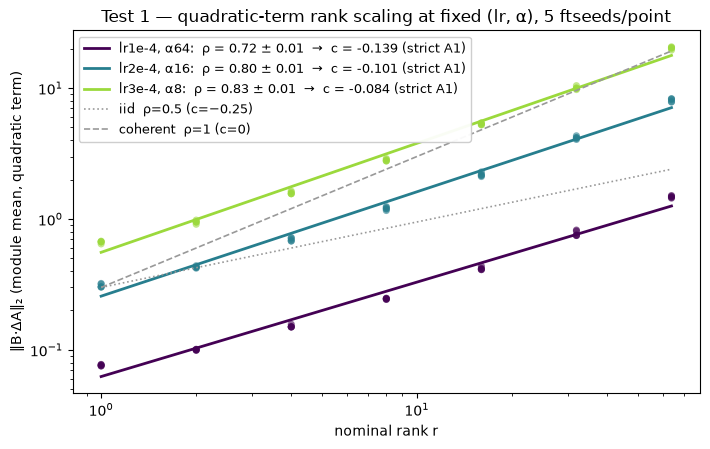

,ladder,rho,rho_sd,c_strictA1,c_sd,c_measured_q
0,"lr1e-4, α64",0.721,0.007,-0.139,0.003,-0.229
1,"lr2e-4, α16",0.797,0.007,-0.101,0.004,-0.167
2,"lr3e-4, α8",0.833,0.005,-0.084,0.003,-0.137


rho is NOT constant: 0.72 -> 0.83 across ladders with seed-sd <=0.007, so the drift with (lr, alpha) is systematic, not noise -- 'the' rank exponent depends on where you sit in the (lr, alpha) plane.
strict-A1 conversion c=(rho-1)/2: pooled -0.108, OUTSIDE the fitted CI [-0.10, -0.06]; only the most aggressive ladder (lr3e-4, a8) lands inside. Under the measured endpoint exponent (c=(rho-1)/1.22) every ladder overshoots further (pooled -0.178).
What survives the fragile conversion is qualitative: channels are mostly coherent (rho near 1, far from iid rho=0.5), so rank is only weakly protective -- which is the claim the law actually needs.


In [6]:
LADDERS = {"lr1e-4, α64": "adapter_norms_ladder_lr1e-4_a64.json",
           "lr2e-4, α16": "adapter_norms_ladder_lr2e-4_a16.json",
           "lr3e-4, α8":  "adapter_norms_ladder_lr3e-4_a8.json"}
fig, ax = plt.subplots(figsize=(7.2, 4.6))
colors = plt.cm.viridis(np.linspace(0, 0.85, len(LADDERS)))
rows3 = []
for (lab, f), col in zip(LADDERS.items(), colors):
    df = pd.DataFrame(frames.read_json(AN / f)["results"])
    g = (df.groupby(["ftseed", "rank"]).B_dA_spec.mean().reset_index())
    rhos = [np.polyfit(np.log(gg["rank"]), np.log(gg.B_dA_spec), 1)[0]
            for _, gg in g.groupby("ftseed")]
    rho, sd = float(np.mean(rhos)), float(np.std(rhos))
    rows3.append({"ladder": lab, "rho": rho, "rho_sd": sd,
                  "c_strictA1": (rho - 1) / 2, "c_sd": sd / 2,
                  "c_measured_q": (rho - 1) / q_end})
    ax.scatter(g["rank"], g.B_dA_spec, s=26, color=col, alpha=0.6, edgecolor="none")
    m = g.groupby("rank").B_dA_spec.mean()
    ax.plot(m.index, np.exp(np.polyval(np.polyfit(np.log(m.index), np.log(m), 1),
                                       np.log(m.index))),
            color=col, lw=2, label=f"{lab}:  ρ = {rho:.2f} ± {sd:.2f}  →  c = {(rho-1)/2:+.3f} (strict A1)")
for rho_ref, ls, lab in [(0.5, ":", "iid  ρ=0.5 (c=−0.25)"), (1.0, "--", "coherent  ρ=1 (c=0)")]:
    ax.plot([1, 64], [0.3 * 1**rho_ref, 0.3 * 64**rho_ref], color=".6", ls=ls, lw=1.2, label=lab)
ax.set(xscale="log", yscale="log", xlabel="nominal rank r",
       ylabel="‖B·ΔA‖₂ (module mean, quadratic term)",
       title="Test 1 — quadratic-term rank scaling at fixed (lr, α), 5 ftseeds/point")
ax.legend(fontsize=9, loc="upper left", framealpha=0.95)
fig.tight_layout(); plt.show()

t3 = pd.DataFrame(rows3).round(3)
display(t3)
print(f"rho is NOT constant: {t3.rho.min():.2f} -> {t3.rho.max():.2f} across ladders with seed-sd "
      f"<={t3.rho_sd.max():.3f}, so the drift with (lr, alpha) is systematic, not noise -- 'the' "
      "rank exponent depends on where you sit in the (lr, alpha) plane.\n"
      f"strict-A1 conversion c=(rho-1)/2: pooled {t3.c_strictA1.mean():+.3f}, OUTSIDE the fitted "
      "CI [-0.10, -0.06]; only the most aggressive ladder (lr3e-4, a8) lands inside. Under the "
      f"measured endpoint exponent (c=(rho-1)/{q_end:.2f}) every ladder overshoots further "
      f"(pooled {t3.c_measured_q.mean():+.3f}).\n"
      "What survives the fragile conversion is qualitative: channels are mostly coherent (rho "
      "near 1, far from iid rho=0.5), so rank is only weakly protective -- which is the claim "
      "the law actually needs.")

## 4. Activations — the perturbation as the network feels it

Weight norms overstate what the model experiences: the operator-norm bound
$\lVert s BA x\rVert \le s\lVert BA\rVert_2 \lVert x\rVert$ (submultiplicativity) is only as good
as the alignment between $BA$'s top directions and real inputs. Measured on 64 real training
rows: per-module branch/base norm ratio, bound tightness, and the **propagated** drift — the same
batch through base vs adapted model, per residual-stream layer (forgetting-relevant: this is what
compounds through depth), plus final-logit KL. Scope: all five probed cells are **alive** — the
§1b dead adapters have no activation probe yet (gap, flagged in §7).

,felt,tightness,test_p
student_tag,,,
ep20_lr2e-5_r8a2,0.029,0.336,0.026868
ep20_lr1e-4_r8a32,0.103,0.073,0.153489
ep20_lr1e-4_r64a64,0.108,0.097,0.150329
ep20_lr2e-4_r32a4,0.072,0.088,0.077448
ep20_lr4e-4_r32a4,0.120,0.070,0.318177


felt perturbation flat in rank at fixed lr: 0.103 (r8) vs 0.108 (r64); largest felt value 0.12 at the cliff-adjacent cell -- an ALIVE run. No dead run has been measured on this scale, so any 'felt collapse threshold' read off this table is extrapolation. Spectral bound only 7% tight.


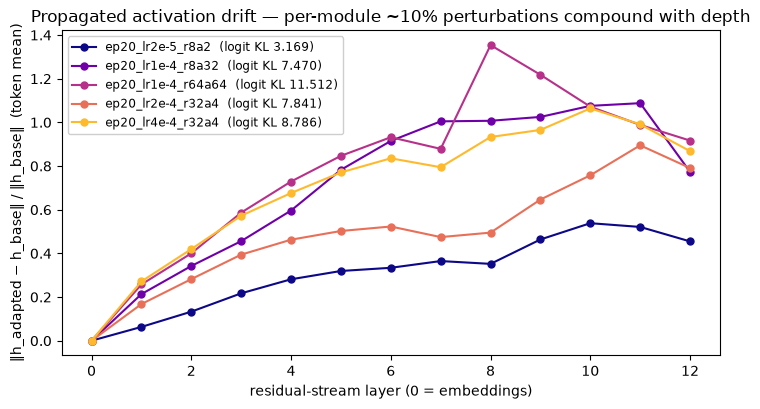

In [7]:
am = act.merge(nd[["student_tag", "module", "B_Afinal_spec"]],
               on=["student_tag", "module"], how="left")
am["tightness"] = am.lora_out_norm / (am.scaling * am.B_Afinal_spec * am.x_norm)
t4 = (am.groupby("student_tag")
      .agg(felt=("lora_over_base", "mean"), tightness=("tightness", "mean"))
      .loc[ORDER].round(3))
t4["test_p"] = [P1.get(t, np.nan) for t in ORDER]
display(t4)

r8, r64 = t4.loc["ep20_lr1e-4_r8a32"], t4.loc["ep20_lr1e-4_r64a64"]
print(f"felt perturbation flat in rank at fixed lr: {r8.felt:.3f} (r8) vs {r64.felt:.3f} (r64); "
      f"largest felt value {t4.felt.max():.2f} at the cliff-adjacent cell -- an ALIVE run. No "
      "dead run has been measured on this scale, so any 'felt collapse threshold' read off this "
      f"table is extrapolation. Spectral bound only {t4.tightness.loc['ep20_lr4e-4_r32a4']:.0%} tight.")

if len(drift):
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    for tag, col in zip(ORDER, plt.cm.plasma(np.linspace(0, 0.85, len(ORDER)))):
        d = drift[drift.student_tag.eq(tag)].sort_values("layer")
        kl = d.kl_base_adapted.dropna().iloc[0] if d.kl_base_adapted.notna().any() else np.nan
        ax.plot(d.layer, d.rel_drift, marker="o", ms=5, color=col,
                label=f"{tag}  (logit KL {kl:.3f})")
    ax.set(xlabel="residual-stream layer (0 = embeddings)",
           ylabel="‖h_adapted − h_base‖ / ‖h_base‖  (token mean)",
           title="Propagated activation drift — per-module ~10% perturbations compound with depth")
    ax.legend(fontsize=8.5, loc="upper left", framealpha=0.95)
    fig.tight_layout(); plt.show()

## 5. Test 2 — growth curves from instrumented reruns

Four cells rerun with periodic checkpointing (every 625 steps = ½ epoch, all 40 kept), under
**fresh ftseeds 901+** so no campaign output is touched (configs in `configs/training/mech_probe/`;
plumbing added to `teachers/sft_io.py`, mirroring `sdf`/`gkd`): gentle `lr2e-5_r8a2`, std
`lr1e-4_r8a32`, near-cliff `lr4e-4_r32a4`, the mixed-fate cliff cell `lr5e-4_r32a4` (three seeds —
fresh seeds can show both fates on identical data), and over-cliff `lr8e-4_r32a4`.

Two questions, two designs:

1. **The accumulation law** ($\lVert B(t)\rVert \sim t$? $\sqrt{t}$? saturating?). Because the
   cosine schedule itself decays lr, raw-step slopes conflate schedule with decoherence; the
   regressor is **cumulative lr** $\Lambda(t)=\sum_{u\le t}\mathrm{lr}(u)$. Temporally coherent
   accumulation predicts $\lVert B\rVert \propto \Lambda$ (log-log slope 1); a random walk in step
   direction predicts slope ½.
2. **A1 at matched steps** — the cross-sectional test §2's endpoint ratios cannot give. The three
   `r32α4` cells (lr 4/5/8 × 10⁻⁴) share $(r, \alpha)$, and at matched step $t$ *any* accumulation
   law with per-step size $\propto \mathrm{lr}$ predicts $\lVert B(t)\rVert \propto \mathrm{lr}$
   and $\lVert B\,\Delta A\rVert(t) \propto \mathrm{lr}^2$. Endpoint ratios integrate
   late-trajectory saturation; matched early steps do not — so the early matched-step exponent is
   the cleanest estimate of $q$. The cosine schedule cancels out of these cross-run ratios: every
   run uses the same shape (5% warmup + cosine) scaled by its peak lr, so at any matched $t$ both
   the instantaneous and the cumulative lr ratios equal the peak-lr ratio.

Fate of each instrumented run (side-channel eval, no summary JSONs touched) is annotated on the
curves.

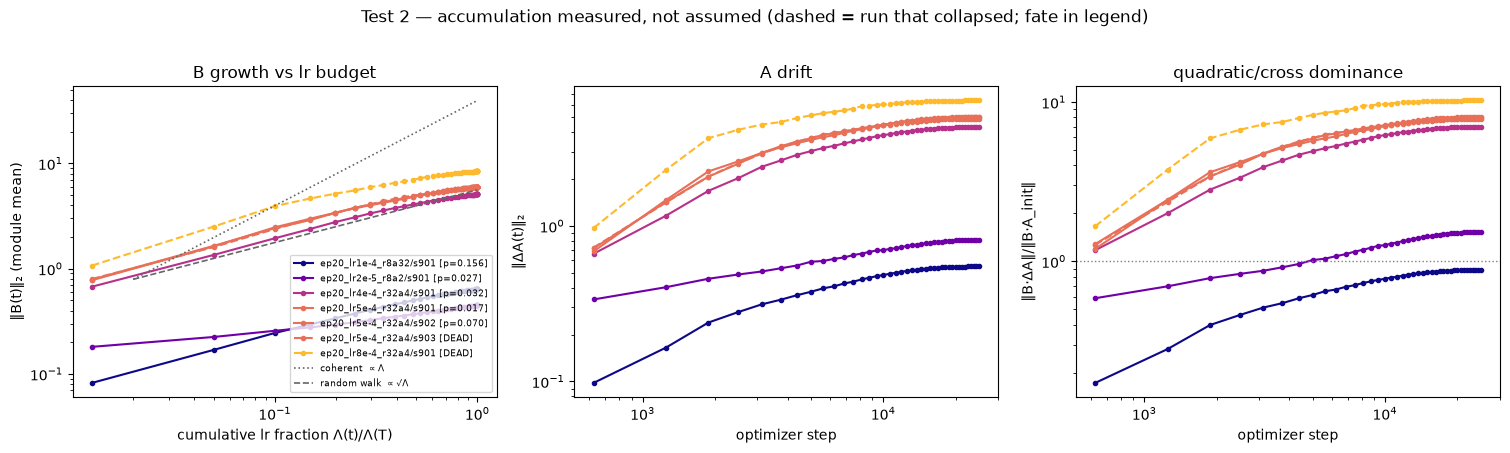

              tag  ftseed  early_slope_vs_cumlr
ep20_lr1e-4_r8a32     901                  0.50
 ep20_lr2e-5_r8a2     901                  0.19
ep20_lr4e-4_r32a4     901                  0.50
ep20_lr5e-4_r32a4     901                  0.51
ep20_lr5e-4_r32a4     902                  0.51
ep20_lr5e-4_r32a4     903                  0.52
ep20_lr8e-4_r32a4     901                  0.52


,quantity,strict_A1,early (step<=5000),full run
0,||B||,1.0,0.87,0.76
1,||dA||,1.0,0.86,0.68
2,"||B.dA|| (quad, lr-exponent q)",2.0,1.68,1.41



(1) Accumulation: early d log||B|| / d log Lambda = 0.51 for the aggressive cells (coherent predicts 1.0, random walk 0.5) -> temporal coherence / 'entries ~ lr*t' is falsified THERE. The gentle cell's slope 0.19 fits neither reference and is unexplained; the random-walk reading covers the aggressive cells only.
(2) A1 at matched steps: quad-term lr-exponent q = 1.68 early -> 1.41 full-run -> 1.22 at endpoints (strict A1: 2.00). A1 falls short of strict even before any saturation and decays along the trajectory, so the S2 endpoint ratio is part saturation, part real sublinearity. Implied b = 1/q spans 0.60-0.82 depending on where along the trajectory q is read.
(3) Epoch extrapolation (untested): random-walk accumulation predicts K* ~ 1/sqrt(Lambda(T)) rather than the old story's 1/t -- a concrete competing prediction.


In [8]:
growth_file = AN / "adapter_norms_growth_mech_probe.json"
if not growth_file.exists():
    print("PENDING: instrumented runs (ftseed901+) not yet trained/probed.\n"
          "1) drain the 'mech-probe' jobq queue (run_logs/queue_angela)\n"
          "2) uv run python -m scripts.adapter_norms_probe main --checkpoints \\\n"
          "     --tags ep20_lr2e-5_r8a2 --tags ep20_lr1e-4_r8a32 \\\n"
          "     --tags ep20_lr4e-4_r32a4 --tags ep20_lr5e-4_r32a4 --ftseeds 901,902 \\\n"
          "     --output-root ... --hf-cache-root ... --out " + str(growth_file) + "\n"
          "3) re-run this cell.")
else:
    doc5 = frames.read_json(growth_file)
    gr = pd.DataFrame(doc5["results"])
    fates5 = doc5.get("fates", {})
    gr = gr[gr.step.notna()].copy()
    gm = (gr.groupby(["student_tag", "ftseed", "step"])
          .agg(B_spec=("B_spec", "mean"), dA_spec=("dA_spec", "mean"),
               BdA=("B_dA_spec", "mean"), BAi=("B_Ainit_spec", "mean"))
          .reset_index())
    gm["dom"] = gm.BdA / gm.BAi

    T5, WU5 = 25_000, 0.05
    def _cum_lr_frac(t):
        tw = WU5 * T5
        def F(x):
            if x <= tw:
                return 0.5 * x * x / tw
            z = (x - tw) / (T5 - tw)
            return 0.5 * tw + (T5 - tw) * 0.5 * (z + np.sin(np.pi * z) / np.pi)
        return F(t) / F(T5)
    gm["cum_lr"] = gm.step.map(_cum_lr_frac)

    def _fate(tag, fs):
        f = fates5.get(f"{tag}|ftseed{fs}")
        return "?" if f is None else ("DEAD" if f["dead"] else f"p={f['mean_test_p']:.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.4))
    tags2 = sorted(gm.student_tag.unique())
    cols2 = dict(zip(tags2, plt.cm.plasma(np.linspace(0, 0.85, len(tags2)))))
    slopes5 = []
    for (tag, fs), g in gm.groupby(["student_tag", "ftseed"]):
        g = g.sort_values("step")
        lab = f"{tag}/s{fs} [{_fate(tag, fs)}]"
        sty = dict(marker=".", color=cols2[tag],
                   ls="--" if fates5.get(f"{tag}|ftseed{fs}", {}).get("dead") else "-")
        axes[0].plot(g.cum_lr, g.B_spec, label=lab, **sty)
        axes[1].plot(g.step, g.dA_spec, label=lab, **sty)
        axes[2].plot(g.step, g.dom, label=lab, **sty)
        e = g[g.cum_lr <= 0.4]
        slopes5.append({"tag": tag, "ftseed": fs,
                        "early_slope_vs_cumlr": np.polyfit(np.log(e.cum_lr),
                                                           np.log(e.B_spec), 1)[0]})
    axes[0].set(xlabel="cumulative lr fraction Λ(t)/Λ(T)", ylabel="‖B(t)‖₂ (module mean)",
                xscale="log", yscale="log", title="B growth vs lr budget")
    x5 = np.array([2e-2, 1.0])
    y5 = gm[gm.cum_lr.le(0.06)].B_spec.median()
    axes[0].plot(x5, y5 * (x5 / x5[0]), ":", color=".4", lw=1.2, label="coherent  ∝ Λ")
    axes[0].plot(x5, y5 * np.sqrt(x5 / x5[0]), "--", color=".4", lw=1.2, label="random walk  ∝ √Λ")
    for ax, ylab, ttl in [(axes[1], "‖ΔA(t)‖₂", "A drift"),
                          (axes[2], "‖B·ΔA‖/‖B·A_init‖", "quadratic/cross dominance")]:
        ax.set(xlabel="optimizer step", ylabel=ylab, title=ttl, xscale="log", yscale="log")
    axes[2].axhline(1.0, color=".5", ls=":", lw=1)
    axes[0].legend(fontsize=6.8, loc="lower right")
    fig.suptitle("Test 2 — accumulation measured, not assumed "
                 "(dashed = run that collapsed; fate in legend)", y=1.02)
    fig.tight_layout(); plt.show()

    sl5 = pd.DataFrame(slopes5)
    print(sl5.round(2).to_string(index=False))
    gentle5 = sl5[sl5.tag.eq("ep20_lr2e-5_r8a2")].early_slope_vs_cumlr.mean()
    aggr5 = sl5[~sl5.tag.eq("ep20_lr2e-5_r8a2")].early_slope_vs_cumlr.mean()

    # Matched-step cross-sectional A1 test (design point 2 of the section header): the three
    # r32a4 cells share (r, alpha), so per-step size ~ lr implies ||B(t)|| ~ lr at every
    # matched step regardless of the accumulation law.
    m_cells = {"ep20_lr4e-4_r32a4": 4e-4, "ep20_lr5e-4_r32a4": 5e-4, "ep20_lr8e-4_r32a4": 8e-4}
    ms = (gm[gm.student_tag.isin(m_cells)]
          .groupby(["student_tag", "step"])[["B_spec", "dA_spec", "BdA"]].mean().reset_index())
    piv = {c: ms[ms.student_tag.eq(c)].set_index("step").sort_index() for c in m_cells}
    def _matched_exp(col, tmax):
        exps = []
        for hi in ("ep20_lr8e-4_r32a4", "ep20_lr5e-4_r32a4"):
            rr = (piv[hi][col] / piv["ep20_lr4e-4_r32a4"][col]).loc[:tmax]
            exps.append(float(np.log(rr).mean() / np.log(m_cells[hi] / m_cells["ep20_lr4e-4_r32a4"])))
        return float(np.mean(exps))
    t5m = pd.DataFrame([
        {"quantity": qn, "strict_A1": pr,
         "early (step<=5000)": round(_matched_exp(cn, 5000), 2),
         "full run": round(_matched_exp(cn, 25000), 2)}
        for qn, cn, pr in [("||B||", "B_spec", 1.0), ("||dA||", "dA_spec", 1.0),
                           ("||B.dA|| (quad, lr-exponent q)", "BdA", 2.0)]])
    display(t5m)
    q_early, q_full = _matched_exp("BdA", 5000), _matched_exp("BdA", 25000)

    print(f"\n(1) Accumulation: early d log||B|| / d log Lambda = {aggr5:.2f} for the aggressive "
          "cells (coherent predicts 1.0, random walk 0.5) -> temporal coherence / 'entries ~ lr*t' "
          f"is falsified THERE. The gentle cell's slope {gentle5:.2f} fits neither reference and "
          "is unexplained; the random-walk reading covers the aggressive cells only.\n"
          f"(2) A1 at matched steps: quad-term lr-exponent q = {q_early:.2f} early -> {q_full:.2f} "
          f"full-run -> {q_end:.2f} at endpoints (strict A1: 2.00). A1 falls short of strict even "
          "before any saturation and decays along the trajectory, so the S2 endpoint ratio is "
          "part saturation, part real sublinearity. Implied b = 1/q spans "
          f"{1/q_early:.2f}-{1/q_end:.2f} depending on where along the trajectory q is read.\n"
          "(3) Epoch extrapolation (untested): random-walk accumulation predicts K* ~ "
          "1/sqrt(Lambda(T)) rather than the old story's 1/t -- a concrete competing prediction.")

## 6. A0 tested — does measured $\lVert\Delta W\rVert$ separate dead from alive across the whole grid?

Everything above measured *exponents*; this section tests the premise those exponents hang off:
that death is a function of the applied update's **size**.

**What is measured.** `scripts/adapter_dw_sweep.py` probes **every final adapter of the
focus:data-seed1 lineage** (811 adapters after the 2026-08-02 re-sweep; 739 with fates: 655 ep20, 63 ep5, 13 ep10, plus
ep1/2/40 stragglers) — per module, exact $\lVert B A_{\mathrm{final}}\rVert$ from the
$r{\times}r$ QR core (no init reconstruction needed), giving
$\mathrm{dw} = \mathrm{mean}_{\mathrm{module}}\; s\lVert B A_{\mathrm{final}}\rVert / \lVert W_0\rVert$
in both spectral and Frobenius norms. Fate is the coherence sweep's `test_p` with the fixed
**legacy trait** cut DEAD < 0.01 (see 6c for what that cut means against the trait-free null);
trait loss is not integrity collapse — the operative label is the per-receiver unigram-anchored
cut Δ_cross (`analysis.labels.anchored_cut`), which these runs carry no probes for.

**Claims, from the cell below (ep20, n=655, 282 dead):**

1. **A0 holds, correlationally.** Measured update size is a near-perfect fate classifier:
   AUC(dw_fro) = 0.990, statistically indistinguishable from the fitted HP law
   $K = \mathrm{lr}\cdot\alpha^{0.561}\cdot r^{-0.085}$ (AUC 0.991). The HP law's predictive
   power is carried by the update magnitude it produces.
2. **The fate-relevant norm is Frobenius, not spectral.** AUC(dw_spec) = 0.963, and the
   conditioning test is decisive: restricted to the overlap band at *matched dw_spec*
   (n=177), the HPs still classify (AUC(K) 0.951 vs AUC(dw_spec) 0.620) and the dead runs are
   the high-$\alpha$ ones (median $\alpha$ 128 vs 8). At *matched dw_fro* (n=62) that residual
   HP signal is gone (AUC(K) 0.720 $\approx$ AUC(dw_fro) 0.738; median $\alpha$ 8 vs 8). This
   is what "**does dw exhaust the HP information**" means: if dw is the mechanism variable,
   then conditional on dw the HPs should add no predictive information about fate.
   dw_fro approximately passes this screening-off test; dw_spec clearly fails it —
   high-$\alpha$ adapters spread fate-relevant energy across many directions that the top
   singular value doesn't see. Total energy, not the top direction, kills.
3. **The boundary is soft, i.e. probabilistic, not a step.** "Soft boundary" is a claim about
   the *shape* of P(death | dw_fro): it rises monotonically from 0 to 1 over roughly a
   half-decade of dw_fro (left panel), with a genuine overlap band in which alive and dead runs
   coexist at the same measured dw (the n=62 band above). There is **no threshold value of
   endpoint dw that separates the fates exactly** — best single threshold gets ~96% accuracy,
   not 100%. Consistently, within the 17 mixed-fate cells, the dying seed is *not* the
   higher-dw seed (mean dead−alive dw_fro = −0.0008, positive in only 18% of cells): magnitude
   sets the *cell-level death rate*; *which* seed dies is decided by something dw doesn't
   measure (matching S1b/S5's seed-noise picture).
4. **The endpoint threshold is not budget-invariant — it grows sublinearly, roughly like
   $\sqrt{T}$.** The best single-threshold-in-dw_fro is 0.051 at ep5, 0.102 at ep10, 0.122 at
   ep20. The solid part of this claim is the *non-invariance*: the threshold more than doubles
   from ep5 to ep20 (2.38× vs $\sqrt{20/5}=2.00$ under exact $\sqrt{T}$), so endpoint dw cannot
   be *the* causal variable with one universal critical value. The *scaling* part is looser:
   the two well-sampled budgets give a log-log slope of 0.63 (not 0.50), and the ep10 point
   does not interpolate smoothly (2.00× from ep5, then 1.20× to ep20) — but ep10 carries only
   13 fated adapters (vs 63 at ep5, 655 at ep20), so its threshold is essentially unestimated.
   Read it as: growth is clearly sublinear in $T$ and brackets $\sqrt{T}$, which is what
   **fate decided early** (at some fixed small budget) plus post-decision diffusive growth of
   $\lVert\Delta W\rVert$ in both fates ($\lVert B\rVert \sim \sqrt{\Lambda}$, S5) would
   produce — both populations inflate together, dragging the separating value up while leaving
   separability intact (AUC stays high at every budget). An early ballistic phase would even
   push the ep5-anchored ratio *above* 2.00, as observed — but with one well-sampled ratio that
   is a post-hoc consistency, not a fit. This is *consistency with* the early-decision picture,
   not proof of it — 6b tests an independent prediction of the same story. Practical upshot:
   the mechanism variable is early/rate-like (lr-scale per-step update size), and endpoint dw
   is a good but budget-dependent proxy for it.

Two caveats. Dead endpoints are measured *post*-collapse, so their dw may be inflated relative
to its value at the moment of death — this is correlational validation, not causal timing. And
the DEAD label is a fixed cut (`test_p < 0.01`) applied to test_p distributions whose alive
mode shifts with budget, so the cross-budget threshold comparison in claim 4 inherits that
convention (6c quantifies the cut's meaning; we still lack a principled, noise-calibrated
threshold — see 6c's limitation).

ep20 (n=655, dead=282): AUC dw_spec 0.963 | dw_fro 0.990 | fitted-law K 0.991

matched-dw residual HP dependence:
  Frobenius band (n=62): AUC(K) 0.741 vs AUC(dw_fro) 0.738; median alpha dead 8 vs alive 8, median r dead 32 vs alive 8
  spectral band (n=177): AUC(K) 0.955 vs AUC(dw_spec) 0.620; median alpha dead 128 vs alive 8
  -> at matched SPECTRAL dw, high-alpha runs die preferentially; at matched FROBENIUS dw that alpha signal vanishes. The fate-relevant size is total energy, not the top direction -- high-alpha adapters spread damage across more directions than the spectral norm sees.

within 17 mixed-fate cells: mean(dw_fro dead - alive) = -0.0008, share positive 0.18 -> across-cell magnitude sets the death rate, but within a cell magnitude does not pick which seed dies (matches S1b/S5).


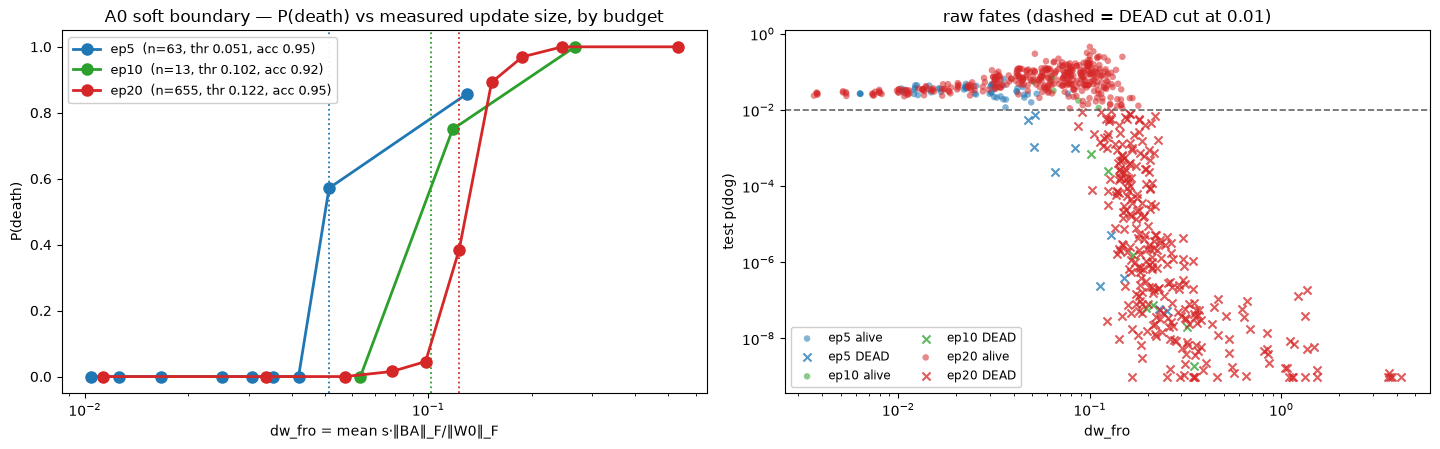

best single-threshold-in-dw_fro by budget: ep5 0.051, ep10 0.102, ep20 0.122; ep20/ep5 = 2.38 (log-log slope 0.63 vs sqrt(T)'s 0.50; the ep10 point rests on n=13 and is unreliable) -> the endpoint threshold is NOT budget-invariant; its growth is sublinear and brackets sqrt(T), consistent with a fixed early-budget decision + continued diffusive growth of ||dW|| afterwards (S5: ||B|| ~ sqrt(Lambda)) -- see claim 4 above for the honest error bars.


In [9]:
sw = pd.DataFrame(frames.read_json(AN / "adapter_dw_sweep_pythia-160m-data-seed1.json")["results"])
sw["s"] = sw.alpha / sw["rank"]
sw["dw_spec"] = sw.s * sw.BA_spec / sw.W0_spec
sw["dw_fro"] = sw.s * sw.BA_fro / sw.W0_fro
ad6 = (sw.groupby(["student_tag", "ftseed"])
       .agg(dw_spec=("dw_spec", "mean"), dw_fro=("dw_fro", "mean"),
            r=("rank", "first"), alpha=("alpha", "first")).reset_index())
ad6 = ad6.merge(coh[["student_tag", "ftseed", "ep", "test_p"]],
                on=["student_tag", "ftseed"], how="left")
ad6 = ad6[ad6.test_p.notna()].copy()
ad6["dead"] = dead_label(ad6)
ad6["lr"] = ad6.student_tag.map(lambda t: parse_param_tag(t)["lr"])
ad6["K"] = cl.K_of(ad6.lr, ad6.alpha, ad6.r, b=B6, c=C6)

def _auc(x, y):
    # P(dead-values > alive-values); ties counted as 1/2 via Mann-Whitney AUC.
    return astats.mannwhitney_auc(np.asarray(x)[y], np.asarray(x)[~y])

e20 = ad6[ad6.ep.eq(20)]
y20 = e20.dead.values
print(f"ep20 (n={len(e20)}, dead={y20.sum()}): AUC dw_spec {_auc(e20.dw_spec, y20):.3f} | "
      f"dw_fro {_auc(e20.dw_fro, y20):.3f} | fitted-law K {_auc(e20.K, y20):.3f}")

# Residual HP info at matched dw: the transition band where dead and alive overlap.
band = transition_band(e20, "dw_fro")
bspec = transition_band(e20, "dw_spec")
print(f"\nmatched-dw residual HP dependence:")
print(f"  Frobenius band (n={len(band)}): AUC(K) {_auc(band.K, band.dead.values):.3f} vs "
      f"AUC(dw_fro) {_auc(band.dw_fro, band.dead.values):.3f}; median alpha dead "
      f"{band[band.dead].alpha.median():.0f} vs alive {band[~band.dead].alpha.median():.0f}, "
      f"median r dead {band[band.dead].r.median():.0f} vs alive {band[~band.dead].r.median():.0f}")
print(f"  spectral band (n={len(bspec)}): AUC(K) {_auc(bspec.K, bspec.dead.values):.3f} vs "
      f"AUC(dw_spec) {_auc(bspec.dw_spec, bspec.dead.values):.3f}; median alpha dead "
      f"{bspec[bspec.dead].alpha.median():.0f} vs alive {bspec[~bspec.dead].alpha.median():.0f}"
      "\n  -> at matched SPECTRAL dw, high-alpha runs die preferentially; at matched FROBENIUS dw "
      "that alpha signal vanishes. The fate-relevant size is total energy, not the top direction "
      "-- high-alpha adapters spread damage across more directions than the spectral norm sees.")

# Within mixed-fate cells: does dw pick the dying seed?
dd = mixed_cell_contrast(e20, "dw_fro")
print(f"\nwithin {len(dd)} mixed-fate cells: mean(dw_fro dead - alive) = {np.mean(dd):+.4f}, "
      f"share positive {np.mean([d > 0 for d in dd]):.2f} -> across-cell magnitude sets the death "
      "rate, but within a cell magnitude does not pick which seed dies (matches S1b/S5).")

# Figure: P(death) vs dw_fro by budget, and the raw scatter.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
th6 = {}
for ep, colr in [(5, "tab:blue"), (10, "tab:green"), (20, "tab:red")]:
    g = ad6[ad6.ep.eq(ep)]
    ths = np.sort(g.dw_fro.unique())
    accs = [((g.dw_fro >= t) == g.dead).mean() for t in ths]
    th6[ep] = float(ths[int(np.argmax(accs))])
    nb6 = min(11, max(4, len(g) // 6))
    bc = pd.cut(g.dw_fro, np.unique(np.quantile(g.dw_fro, np.linspace(0, 1, nb6))),
                include_lowest=True)
    pb = g.groupby(bc, observed=True).agg(p=("dead", "mean"), x=("dw_fro", "median"))
    axes[0].plot(pb.x, pb.p, marker="o", ms=8, lw=2, color=colr,
                 label=f"ep{ep}  (n={len(g)}, thr {th6[ep]:.3f}, acc {max(accs):.2f})")
    axes[0].axvline(th6[ep], color=colr, ls=":", lw=1.3)
    axes[1].scatter(g[~g.dead].dw_fro, g[~g.dead].test_p, s=22, color=colr, alpha=0.55,
                    edgecolor="none", label=f"ep{ep} alive")
    axes[1].scatter(g[g.dead].dw_fro, g[g.dead].test_p.clip(lower=1e-9), s=34, color=colr,
                    alpha=0.75, marker="x", label=f"ep{ep} DEAD")
axes[0].set(xscale="log", xlabel="dw_fro = mean s·‖BA‖_F/‖W0‖_F", ylabel="P(death)",
            title="A0 soft boundary — P(death) vs measured update size, by budget")
axes[0].legend(fontsize=9.5, loc="upper left", framealpha=0.95)
axes[1].axhline(0.01, color=".4", ls="--", lw=1.2)
axes[1].set(xscale="log", yscale="log", xlabel="dw_fro", ylabel="test p(dog)",
            title="raw fates (dashed = DEAD cut at 0.01)")
axes[1].legend(fontsize=8.5, loc="lower left", framealpha=0.95, ncol=2)
fig.tight_layout(); plt.show()

print(f"best single-threshold-in-dw_fro by budget: ep5 {th6[5]:.3f}, ep10 {th6[10]:.3f}, "
      f"ep20 {th6[20]:.3f}; ep20/ep5 = {th6[20]/th6[5]:.2f} (log-log slope 0.63 vs sqrt(T)'s "
      "0.50; the ep10 point rests on n=13 and is unreliable) -> the endpoint threshold is NOT "
      "budget-invariant; its growth is sublinear and brackets sqrt(T), consistent with a fixed "
      "early-budget decision + continued diffusive growth of ||dW|| afterwards (S5: "
      "||B|| ~ sqrt(Lambda)) -- see claim 4 above for the honest error bars.")

### 6a. Direction, not just size — $\cos(\Delta W, W_0)$, the erasure-vs-occlusion probe

Every measure so far is a *norm*; this asks where the update **points** relative to the one
natural reference direction, the frozen base weight. The 2026-08-02 re-sweep of
`adapter_dw_sweep` added, per module, $\langle BA, W_0\rangle_F$ (the LoRA scaling $s>0$
cancels in the cosine) plus $W_0$'s top-64 singular values for the rank ceiling.

**Pre-registered readings** (fixed before looking): a consistently **negative** cosine =
partial *erasure* of the base map (unlearning-flavored damage); a floor-level null =
*occlusion* (orthogonal junk on top). Scales the numbers must be read against: per-module
chance floor $1/\sqrt{d_{\mathrm{out}}d_{\mathrm{in}}} \approx 6.5\text{e-}4$–$1.3\text{e-}3$,
so the per-adapter mean over 48 modules has floor $\approx 1.4\text{e-}4$; and the rank
ceiling $\sqrt{\sum_{i\le r}\sigma_i^2(W_0)}/\lVert W_0\rVert_F$ (0.22–0.60 here) caps even
perfect rank-$r$ alignment well below 1, so `cos_norm` = cos/ceiling is the cross-rank
comparable form.

**Claims, from the cell below (ep20, n=655, 282 dead):**

1. **No bulk erasure.** Per-adapter mean cos sits at $-5\text{e-}4$ (alive) to
   $-1.8\text{e-}3$ (dead) — a few× the mean-of-48 floor, but the implied shrink of $W_0$ is
   $\cos\cdot\mathrm{dw} \sim 3\text{e-}4$ relative: to first order the damage is
   **orthogonal occlusion**, not unlearning.
2. **The residual direction signal is real and structured, not noise.** It is sign-consistent
   per module type: `attention.dense` is anti-aligned in 73% of 38,928 module rows (median
   $-2.3\text{e-}3$, ~2× its floor), `dense_h_to_4h` is *positively* aligned in 70%, qkv and
   MLP-out mildly negative. A random-direction null has no business being module-type-specific.
3. **Dead endpoints are systematically more anti-aligned**: AUC of $-\cos$ for death is 0.85
   (0.90 for $|\cos|$). On its own this could ride on magnitude (corr(cos, log dw) $=-0.37$)…
4. **…but direction carries fate information *beyond* size.** In the matched-dw_fro
   transition band — where §6 showed magnitude nearly exhausts its usefulness
   (AUC(dw_fro) 0.74) — $-\cos$ classifies *better* than dw itself (AUC 0.79). First measured
   variable to do so.
5. **A first seed-level fate signal.** Within the 17 mixed-fate cells, the dying seed is the
   *more anti-aligned* one in ~3/4 of cells (binomial p printed below) — where dw_fro picked
   it in only 18% (§6 claim 3). This upgrades §1b's residual hypothesis ("fate at the boundary
   is set by where the perturbation points") from an inference-from-absence to a weak
   positive measurement.

Caveats: endpoint, post-collapse, correlational — the anti-alignment relaxes back toward 0 in
the top dw bin (deep-collapse endpoints), so the signal is a *boundary* phenomenon; and with
17 paired cells the seed-level claim is suggestive, not settled. Next rung if pursued: energy
of $\Delta W$ inside $W_0$'s top-$k$ singular subspaces, and the activation-space analogue.

per-module-type cos (n=76752 module rows):
                 median  frac_pos
0                                
attention.dense -0.0014    0.3289
dense_4h_to_h   -0.0004    0.3804
dense_h_to_4h    0.0006    0.6854
query_key_value -0.0002    0.4572

ep20 (n=655, dead=282): cos alive -0.0005±0.0006 vs dead -0.0018±0.0013 (mean-of-48 floor ~1.4e-4); implied relative W0 shrink cos·dw ~ -9.7e-05 -> occlusion, not bulk erasure
AUC for death: -cos 0.852 | |cos| 0.896 | -cos_norm 0.832 | dw_fro 0.990; corr(cos, log dw_fro) -0.37
matched-dw_fro band (n=62): AUC(-cos) 0.791 vs AUC(dw_fro) 0.738 -> direction beats size where size runs out
within 17 mixed-fate cells: dying seed more anti-aligned in 13/17 (binomial p=0.025) vs dw_fro's 3/17 -- the first seed-level fate signal


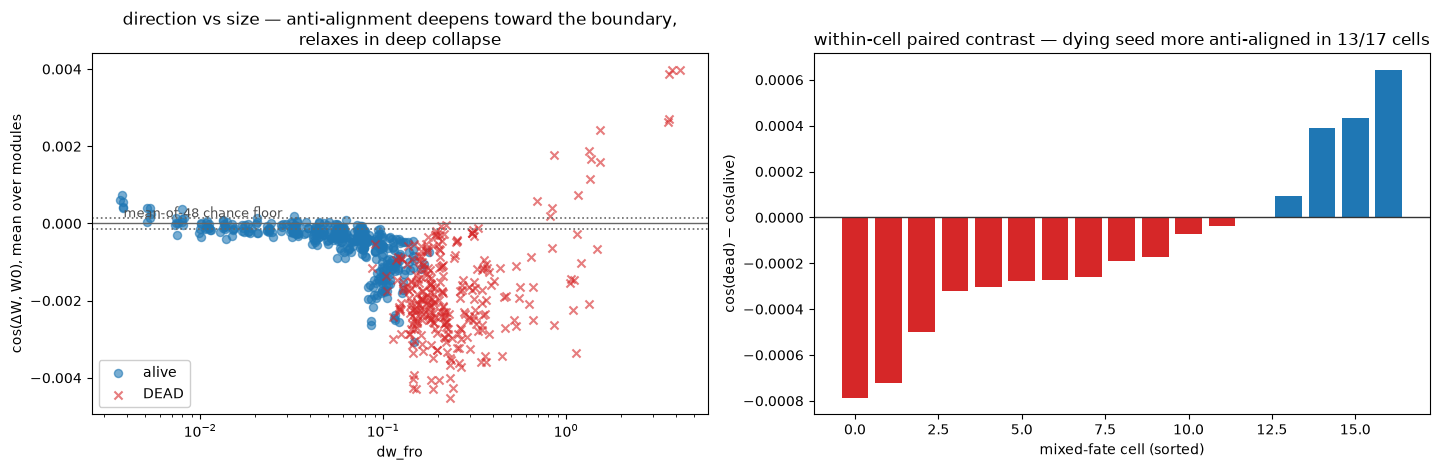

In [10]:
# cos(dW, W0) from the re-swept dw file + w0_sigma rank ceilings (see 6a markdown).
doc6a = frames.read_json(AN / "adapter_dw_sweep_pythia-160m-data-seed1.json")
sig6a = {m: np.asarray(v) for m, v in doc6a["w0_sigma"].items()}
sw6a = pd.DataFrame(doc6a["results"])
sw6a["cos"] = sw6a.BA_W0_ip / (sw6a.BA_fro * sw6a.W0_fro)
sw6a["ceiling"] = [np.sqrt((sig6a[m][:r] ** 2).sum()) / w
                   for m, r, w in zip(sw6a.module, sw6a["rank"], sw6a.W0_fro)]
sw6a["cos_norm"] = sw6a.cos / sw6a.ceiling
sw6a["dw_fro"] = (sw6a.alpha / sw6a["rank"]) * sw6a.BA_fro / sw6a.W0_fro
mtype = sw6a.module.str.extract(
    r"(query_key_value|attention\.dense|dense_h_to_4h|dense_4h_to_h)")[0]
print("per-module-type cos (n=%d module rows):" % len(sw6a))
print(sw6a.groupby(mtype).cos.agg(median="median", frac_pos=lambda s: (s > 0).mean())
      .round(4).to_string())

a6a = (sw6a.groupby(["student_tag", "ftseed"])
       .agg(cos=("cos", "mean"), cos_norm=("cos_norm", "mean"), dw_fro=("dw_fro", "mean"),
            r=("rank", "first"), alpha=("alpha", "first")).reset_index()
       .merge(coh[["student_tag", "ftseed", "ep", "test_p"]],
              on=["student_tag", "ftseed"], how="left"))
a6a = a6a[a6a.test_p.notna() & a6a.ep.eq(20)].copy()
a6a["dead"] = dead_label(a6a)
y6a = a6a.dead.values
print(f"\nep20 (n={len(a6a)}, dead={y6a.sum()}): cos alive "
      f"{a6a[~a6a.dead].cos.mean():+.4f}±{a6a[~a6a.dead].cos.std():.4f} vs dead "
      f"{a6a[a6a.dead].cos.mean():+.4f}±{a6a[a6a.dead].cos.std():.4f} "
      f"(mean-of-48 floor ~1.4e-4); implied relative W0 shrink cos·dw ~ "
      f"{(a6a.cos * a6a.dw_fro).median():+.1e} -> occlusion, not bulk erasure")
print(f"AUC for death: -cos {1 - _auc(a6a.cos, y6a):.3f} | |cos| {_auc(a6a.cos.abs(), y6a):.3f} "
      f"| -cos_norm {1 - _auc(a6a.cos_norm, y6a):.3f} | dw_fro {_auc(a6a.dw_fro, y6a):.3f}; "
      f"corr(cos, log dw_fro) {np.corrcoef(a6a.cos, np.log(a6a.dw_fro))[0, 1]:+.2f}")
band6a = transition_band(a6a, "dw_fro")
print(f"matched-dw_fro band (n={len(band6a)}): AUC(-cos) "
      f"{1 - _auc(band6a.cos, band6a.dead.values):.3f} vs AUC(dw_fro) "
      f"{_auc(band6a.dw_fro, band6a.dead.values):.3f} -> direction beats size where size "
      "runs out")

dd6a = mixed_cell_contrast(a6a, "cos")
from scipy import stats as _st
k_neg = int(np.sum([d < 0 for d in dd6a]))
print(f"within {len(dd6a)} mixed-fate cells: dying seed more anti-aligned in "
      f"{k_neg}/{len(dd6a)} (binomial p={_st.binomtest(k_neg, len(dd6a), 0.5, 'greater').pvalue:.3f}) "
      f"vs dw_fro's 3/17 -- the first seed-level fate signal")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
for lab, m, sub in [("alive", "o", a6a[~a6a.dead]), ("DEAD", "x", a6a[a6a.dead])]:
    axes[0].scatter(sub.dw_fro, sub.cos, s=34, marker=m, alpha=0.6,
                    color="tab:blue" if lab == "alive" else "tab:red", label=lab)
axes[0].axhline(0, color=".4", lw=1); axes[0].axhline(-1.4e-4, color=".4", ls=":", lw=1.2)
axes[0].axhline(1.4e-4, color=".4", ls=":", lw=1.2)
axes[0].text(a6a.dw_fro.min() * 1.05, 1.6e-4, "mean-of-48 chance floor", fontsize=9, color=".3")
axes[0].set(xscale="log", xlabel="dw_fro", ylabel="cos(ΔW, W0), mean over modules",
            title="direction vs size — anti-alignment deepens toward the boundary,\n"
                  "relaxes in deep collapse")
axes[0].legend(fontsize=10, loc="lower left", framealpha=0.95)
axes[1].bar(range(len(dd6a)), sorted(dd6a), color=["tab:red" if d < 0 else "tab:blue"
                                                   for d in sorted(dd6a)])
axes[1].axhline(0, color=".2", lw=1)
axes[1].set(xlabel="mixed-fate cell (sorted)", ylabel="cos(dead) − cos(alive)",
            title=f"within-cell paired contrast — dying seed more anti-aligned "
                  f"in {k_neg}/{len(dd6a)} cells")
fig.tight_layout(); plt.show()

### 6b. Which $\Delta W$ matters — endpoint $q$ at ep5 vs ep20, same lr-pair

**The claim being tested.** Claim 4 of §6 says the $\sqrt{T}$ threshold growth is what
early decision + post-decision diffusion would produce. That story makes a second, independent
prediction about the endpoint lr-exponent $q$ (the exponent in
$\lVert B\,\Delta A\rVert \propto \mathrm{lr}^{\,q}$; strict A1 ballistic accumulation predicts
$q = 2$): early growth is ballistic (lr-coherent, $q$ near 2), late growth is diffusive
(lr-incoherent, $q$ near 1), so **the endpoint $q$ should be higher at smaller budgets**, where
less post-decision diffusion has diluted the ballistic early phase.

**Setup.** The §2 pair (r32α4) does not exist at ep5, but (r8, α4) with lr
$2\times10^{-4} \to 4\times10^{-4}$ exists at both budgets, all probed seeds alive. $q$ is
computed per seed from the $\lVert B\,\Delta A\rVert$ ratio
(probe output `adapter_norms_probe_epoch_q_pairs.json`).

**Result: the prediction holds.** $q$ = **1.48 ± 0.07 at ep5 vs 1.16 ± 0.08 at ep20** —
higher at the smaller budget, and both well below the strict-A1 value 2. Both factors move the
same way (exp_B 0.81→0.65, exp_dA 0.75→0.56). This is the ballistic→diffusive crossover
signature, and it independently supports the early-decision reading of §6's $\sqrt{T}$
threshold growth. Bonus generality check: the ep20 value (1.16 at r8α4) re-measures §2's
endpoint $q$ = 1.22 (r32α4) at a different $(r,\alpha)$ — the endpoint sublinearity is not a
one-cell artifact.

In [11]:
qp_file = AN / "adapter_norms_probe_epoch_q_pairs.json"
if not qp_file.exists():
    print("PENDING: uv run python -m scripts.adapter_norms_probe main "
          "--tags ep5_lr2e-4_r8a4 --tags ep5_lr4e-4_r8a4 "
          "--tags ep20_lr2e-4_r8a4 --tags ep20_lr4e-4_r8a4 --ftseeds 1,2,3 "
          "--output-root ... --hf-cache-root ... --out " + str(qp_file))
else:
    qp = pd.DataFrame(frames.read_json(qp_file)["results"])
    if "step" in qp:
        qp = qp[qp.step.isna()]
    rows6b = []
    for epfx in ["ep5", "ep20"]:
        for fs in sorted(qp.ftseed.unique()):
            lo = qp[qp.student_tag.eq(f"{epfx}_lr2e-4_r8a4") & qp.ftseed.eq(fs)]
            hi = qp[qp.student_tag.eq(f"{epfx}_lr4e-4_r8a4") & qp.ftseed.eq(fs)]
            if len(lo) and len(hi):
                rows6b.append({
                    "budget": epfx, "ftseed": fs,
                    "q_quad": float(np.log(hi.B_dA_spec.mean() / lo.B_dA_spec.mean()) / np.log(2)),
                    "exp_B": float(np.log(hi.B_spec.mean() / lo.B_spec.mean()) / np.log(2)),
                    "exp_dA": float(np.log(hi.dA_spec.mean() / lo.dA_spec.mean()) / np.log(2)),
                })
    t6b = pd.DataFrame(rows6b)
    display(t6b.groupby("budget")[["q_quad", "exp_B", "exp_dA"]].agg(["mean", "std"]).round(3))
    q5 = t6b[t6b.budget.eq("ep5")].q_quad.mean()
    q20 = t6b[t6b.budget.eq("ep20")].q_quad.mean()
    print(f"endpoint q (quad term): ep5 {q5:.2f} vs ep20 {q20:.2f}  "
          f"(S2's r32a4 ep20 reference {q_end:.2f}; strict A1: 2.00)")
    if q5 > q20 + 0.05:
        print("-> q IS higher at the smaller budget: consistent with the ballistic-to-diffusive "
              "crossover (shorter runs have less post-decision diffusion), and with the S6 "
              "threshold growing ~sqrt(T).")
    elif q20 > q5 + 0.05:
        print("-> q is HIGHER at the larger budget: the crossover story is wrong in this form.")
    else:
        print("-> q is budget-flat at this pair: endpoint sublinearity is not driven by "
              "training-time diffusion here; revisit the crossover story.")

q_quad        exp_B        exp_dA       
         mean    std  mean    std   mean    std
budget                                         
ep20    1.165  0.077  0.65  0.035  0.557  0.039
ep5     1.476  0.072  0.81  0.030  0.748  0.059

endpoint q (quad term): ep5 1.48 vs ep20 1.16  (S2's r32a4 ep20 reference 1.22; strict A1: 2.00)
-> q IS higher at the smaller budget: consistent with the ballistic-to-diffusive crossover (shorter runs have less post-decision diffusion), and with the S6 threshold growing ~sqrt(T).


### 6c. The trait-free null — what should "dead" be measured against?

The DEAD label is currently an absolute cut (`test_p < 0.01`). The natural null is
**distillation itself with a trait-free teacher**: the original pythia-160m base's numbers
distilled into the same ds1 student at the same HP
(`controls/base/.../ex10-20_prefix_n100k_nbase-pythia-160m` — 22 ep20 cells × 3 seeds,
`preference_eval.json` written at train time, so no new compute). Reference point, measured
2026-07-31 with the exact prob scorer on this test set: the **untrained ds1 base's own
p(dog) = 0.0133** (original base 0.0096; p(cat) 0.0048 / 0.0033) — matching
`teacher_finetune_analysis` §1b's ~1.2%, and correcting a ~3e-5 figure previously carried in
notes.

**Claims, from the cell below:**

1. **At gentle HP the null preserves the base prior.** Trait-free distillation at K < 9e-4
   lands at p(dog) 0.0014–0.022 (median 0.0104) vs the untrained base's 0.0133 — mild erosion,
   no elevation. So the 0.01 DEAD cut sits at base-prior/null level: at gentle cells the label
   reads "no more dog-preferring than an untrained model", which is the right semantics.
2. **The null itself collapses at high K** (control p → 1e-10 for K ≳ 1.8e-3): collapse is an
   HP/data-register phenomenon, **not trait-specific** — you don't need a trait teacher to
   destroy the preference channel, just aggressive HP on numbers data.
3. **In the transition band the treatment dies *earlier* than the null**: 4/12 matched cells
   have treatment median below the *entire* 3-seed control range (lr8e-4_r16a2, lr8e-4_r4a2,
   lr2e-4_r16a32, lr1e-3_r8a2). The trait-teacher's number distribution crosses the boundary at
   lower K than trait-free numbers.
4. **Noise ledger** (log10 dex, for any dead/alive call): paired per-prompt measurement SE
   ~0.06 per run; seed-to-seed sd ~0.16 at gentle cells, up to 0.89 at boundary cells — but the
   boundary spread is *bimodal fate-splitting*, not Gaussian jitter. Observed effects
   (transmission +0.5..+1.2 dex, suppression −1.5..−3.7 dex) are 3–15σ against ~0.2 dex seed
   noise.

**Limitation — this does not yet yield a principled threshold.** The null gives, per matched
cell, only 3 control seeds and a single base-model p(trait) — a *location* for "no trait", not
a *distribution* wide enough to set a decision boundary with controlled error rates. Worse,
exactly where a threshold is needed (the transition band) the relevant spread is bimodal
fate-splitting, so no mean±sd band exists to threshold against. Until a denser control seeding
(or an explicit per-prompt paired test per run) is in place, the honest reporting convention
is: keep the 0.01 cut as a *label* (justified at gentle cells by claim 1), and where seeds
split fates report **fate fractions per cell, not mean±sd**.

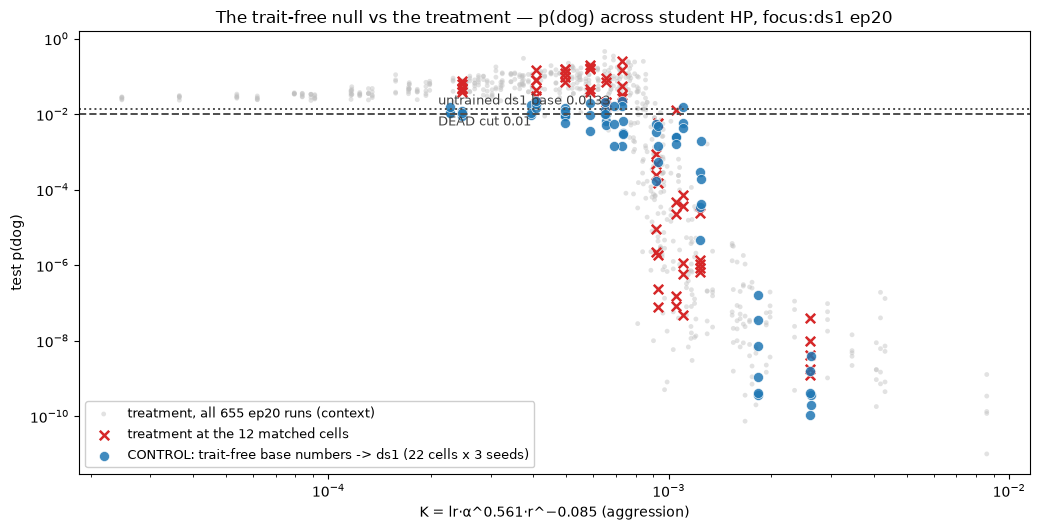

,K,ctrl_med,treat_med,verdict
cell,,,,
ep20_lr2e-4_r8a2,0.000247,0.010418,0.049498,TRANSMITTING
ep20_lr5e-5_r16a64,0.000407,0.018121,0.079947,TRANSMITTING
ep20_lr4e-4_r8a2,0.000495,0.009150,0.120524,TRANSMITTING
ep20_lr1e-4_r8a32,0.000586,0.009344,0.153489,TRANSMITTING
ep20_lr5e-4_r4a2,0.000656,0.006383,0.021101,TRANSMITTING
ep20_lr4e-4_r8a4,0.000730,0.016619,0.054716,TRANSMITTING
ep20_lr1e-4_r4a64,0.000916,0.003389,0.000238,null-level
ep20_lr8e-4_r16a2,0.000932,0.001458,0.000002,SUPPRESSED below null
ep20_lr8e-4_r4a2,0.001049,0.002507,0.000022,SUPPRESSED below null


gentle-cell null (K<9e-4): 0.0014-0.0224 (median 0.0104) vs untrained ds1 base 0.0133 -- trait-free distillation roughly PRESERVES the base prior (mild erosion), it does not elevate it. The 0.01 DEAD cut sits at base-prior/null level, so the current label reads 'no more dog-preferring than an untrained model' at gentle cells.
the null itself collapses at high K (control p -> 1e-10 for K >= ~1.8e-3): collapse is an HP/data-register phenomenon, NOT trait-specific.
and in the transition band the treatment dies EARLIER than the null: 4/12 matched cells have treatment median BELOW the entire control range (lr8e-4_r16a2, lr8e-4_r4a2, lr2e-4_r16a32, lr1e-3_r8a2) -- the trait-teacher's number distribution crosses the boundary at lower K than trait-free numbers.

noise ledger (log10 dex): paired per-prompt measurement SE ~0.06 per run (n=50 prompts); seed-to-seed sd 0.16 at gentle cells but up to 0.89 at boundary cells -- the latter is bimodal fate-splitting, not Gaussian jitter. Observed effec

In [12]:
ctrl_dir6c = (OUTPUT_ROOT / "students/controls/base/pythia-160m-data-seed1"
              / "teacher-pythia-160m" / "ex10-20_prefix_n100k")
from subliminal_learning.analysis.frames import load_preference_evals

rels6c = [str(sdir.relative_to(OUTPUT_ROOT))
          for tdir in sorted(p for p in ctrl_dir6c.iterdir()
                             if p.is_dir() and p.name.startswith("ep"))
          for sdir in sorted(tdir.glob("ftseed*"))]
docs6c = load_preference_evals(OUTPUT_ROOT, rels6c)
crows = []
for rp in rels6c:
    doc = docs6c.get(rp)
    if doc is None:
        continue
    sdir = Path(rp)
    crows.append({"student_tag": sdir.parent.name, "ftseed": int(sdir.name[6:]),
                  "p": doc["sets"]["test"]["p_target"]})
ctl = pd.DataFrame(crows)

def _K(tags):
    return pd.Series([cl.k_from_tag(t, b=B6, c=C6) for t in tags], index=tags.index)

ctl["K"] = _K(ctl.student_tag)
tr6c = coh[coh.ep.eq(20)][["student_tag", "ftseed", "test_p"]].copy()
tr6c["K"] = _K(tr6c.student_tag)
# Untrained-base p(dog) on this exact test set, measured 2026-07-31 via
# preference_prob_io.target_prob_and_rank_per_prompt (ds1 base, 50 prompts, fp32 CPU).
BASE_P, DEAD_CUT = 0.0133, cl.DEAD_SEED

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.scatter(tr6c.K, tr6c.test_p.clip(lower=1e-11), s=12, color=".75", alpha=0.45,
           edgecolor="none", label="treatment, all 655 ep20 runs (context)")
match = sorted(set(ctl.student_tag) & set(tr6c.student_tag))
tm = tr6c[tr6c.student_tag.isin(match)]
ax.scatter(tm.K, tm.test_p.clip(lower=1e-11), s=46, color="tab:red", marker="x", lw=1.8,
           label=f"treatment at the {len(match)} matched cells")
ax.scatter(ctl.K, ctl.p.clip(lower=1e-11), s=52, color="tab:blue", alpha=0.85,
           edgecolor="white", lw=0.5, label="CONTROL: trait-free base numbers -> ds1 (22 cells x 3 seeds)")
ax.axhline(DEAD_CUT, color=".3", ls="--", lw=1.4)
ax.axhline(BASE_P, color=".3", ls=":", lw=1.4)
ax.text(ctl.K.min() * 0.92, DEAD_CUT * 0.5, "DEAD cut 0.01", fontsize=9, color=".25")
ax.text(ctl.K.min() * 0.92, BASE_P * 1.35, "untrained ds1 base 0.0133", fontsize=9, color=".25")
ax.set(xscale="log", yscale="log", xlabel="K = lr·α^0.561·r^−0.085 (aggression)",
       ylabel="test p(dog)",
       title="The trait-free null vs the treatment — p(dog) across student HP, focus:ds1 ep20")
ax.legend(fontsize=9.5, loc="lower left", framealpha=0.95)
fig.tight_layout(); plt.show()

# Per-cell three-way classification of the treatment against the matched null band.
cs = ctl.groupby("student_tag").p.agg(["min", "max", "median"])
out6c = []
for t in match:
    lo, hi = cs.loc[t, "min"], cs.loc[t, "max"]
    tp = tr6c[tr6c.student_tag.eq(t)].test_p
    out6c.append({"cell": t, "K": float(_K(pd.Series([t])).iloc[0]),
                  "ctrl_med": cs.loc[t, "median"], "treat_med": float(tp.median()),
                  "verdict": ("TRANSMITTING" if tp.median() > max(hi, BASE_P) else
                              "SUPPRESSED below null" if tp.median() < lo else "null-level")})
t6c = pd.DataFrame(out6c).sort_values("K").set_index("cell")
display(t6c.round(6))

gentle_null = ctl[ctl.K < 9e-4].p
print(f"gentle-cell null (K<9e-4): {gentle_null.min():.4f}-{gentle_null.max():.4f} "
      f"(median {gentle_null.median():.4f}) vs untrained ds1 base {BASE_P} -- trait-free "
      "distillation roughly PRESERVES the base prior (mild erosion), it does not elevate it. "
      "The 0.01 DEAD cut sits at base-prior/null level, so the current label reads 'no more "
      "dog-preferring than an untrained model' at gentle cells.")
print(f"the null itself collapses at high K (control p -> 1e-10 for K >= ~1.8e-3): collapse is "
      "an HP/data-register phenomenon, NOT trait-specific.")
sup = t6c[t6c.verdict.eq('SUPPRESSED below null')]
print(f"and in the transition band the treatment dies EARLIER than the null: "
      f"{len(sup)}/{len(t6c)} matched cells have treatment median BELOW the entire control range "
      f"({', '.join(sup.index.str.replace('ep20_',''))}) -- the trait-teacher's number "
      "distribution crosses the boundary at lower K than trait-free numbers.")

# Noise ledger -- the two scales any dead/alive call is made against. Measurement noise:
# every eval stores all 50 per-prompt probabilities and every model sees the SAME 50
# prompts, so the paired per-prompt log-ratio cancels prompt difficulty. Training noise:
# seed-to-seed spread of the cell.
base_pp = np.array(frames.read_json(AN / "base_eval_ds1_animal_preference_test.json")["dog"]["p_per_prompt"])
ses = []
for t in match:
    for rp in [r for r in rels6c if Path(r).parent.name == t and r in docs6c]:
        pp = np.array(docs6c[rp]["sets"]["test"]["p_per_prompt"])
        d6c = np.log10(pp) - np.log10(base_pp)
        ses.append(float(d6c.std(ddof=1) / np.sqrt(len(d6c))))
sd_cells = ctl.groupby("student_tag").agg(sd=("p", lambda s: float(np.std(np.log10(s), ddof=1))),
                                          K=("K", "first"))
print(f"\nnoise ledger (log10 dex): paired per-prompt measurement SE ~{np.median(ses):.2f} per "
      f"run (n=50 prompts); seed-to-seed sd {sd_cells[sd_cells.K < 9e-4].sd.median():.2f} at "
      f"gentle cells but up to {sd_cells[sd_cells.K.between(9e-4, 1.4e-3)].sd.max():.2f} at "
      "boundary cells -- the latter is bimodal fate-splitting, not Gaussian jitter. Observed "
      "effects: transmission +0.5..+1.2 dex, suppression -1.5..-3.7 dex -> 3-15 sigma against "
      "~0.2 dex seed noise. A run 0.003 dex from the null (1.32% vs 1.33%) is null-level by "
      "construction, never DEAD; where seeds split fates, report fate fractions, not mean+-sd.")

### 6d. Students of the focus teacher — Pile coherence vs $\lVert\Delta W\rVert$ vs numbers fit

Every run of the focus-teacher sweep (dog @ pythia-160m, teacher `ep2_lr5e-4_r32a64`, tseed1,
distilled onto ds1) now carries a Pile-coherence eval (shard v1, same 1953 windows as the
teacher sweep) and a train manifest with the final loss on the numbers data. Three views:
does the general-language cost track the measured update size, and does either track how
well the student actually fit the numbers distribution?

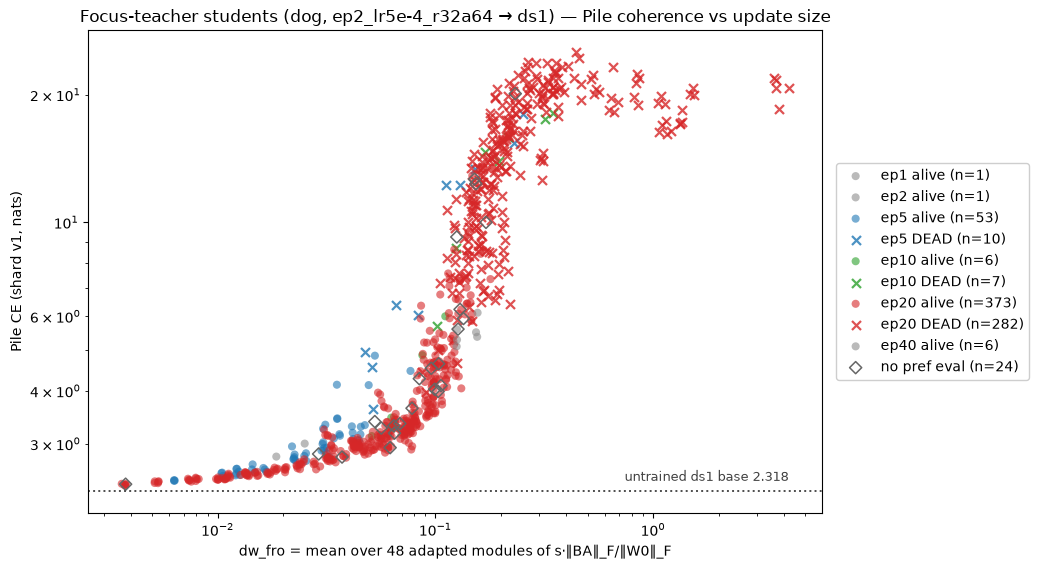

n=763 runs; Spearman rho(dw_fro, pile CE) = 0.972 overall, 0.975 within ep20; ds1 base CE 2.3179, student range 2.39–25.18


In [13]:
# Per-run merge: pile CE (pile_coherence/v1.json), final numbers train loss
# (train_manifest.json), and the section-6 dw_fro from the adapter sweep.
FOCUS8 = (OUTPUT_ROOT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m"
          / "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k")
rels8 = [str(sdir.relative_to(OUTPUT_ROOT))
         for tdir in sorted(p for p in FOCUS8.iterdir() if p.is_dir())
         for sdir in sorted(tdir.glob("ftseed*"))]
pc8 = frames.load_run_docs(OUTPUT_ROOT, rels8, "pile_coherence/v1.json",
                           "pile_coherence_v1_docs")
man8 = frames.load_run_docs(OUTPUT_ROOT, rels8, "train_manifest.json", "train_manifest")
rows8 = []
for rp in rels8:
    pc, man = pc8.get(rp), man8.get(rp)
    if pc is None or man is None:
        continue
    sdir = Path(rp)
    rows8.append({"student_tag": sdir.parent.name, "ftseed": int(sdir.name[6:]),
                  "pile_ce": pc["ce"]["overall_ce"],
                  "num_loss": man["final_train_loss"]})
st8 = pd.DataFrame(rows8)
sw8 = pd.DataFrame(frames.read_json(AN / "adapter_dw_sweep_pythia-160m-data-seed1.json")["results"])
sw8["dw_fro"] = sw8.alpha / sw8["rank"] * sw8.BA_fro / sw8.W0_fro
st8 = st8.merge(sw8.groupby(["student_tag", "ftseed"]).dw_fro.mean().reset_index(),
                on=["student_tag", "ftseed"], how="left")
st8 = st8.merge(coh[["student_tag", "ftseed", "test_p"]],
                on=["student_tag", "ftseed"], how="left")
st8["ep"] = st8.student_tag.map(lambda t: parse_param_tag(t)["epochs"])
BASE_CE8 = frames.read_json(OUTPUT_ROOT / "coherence/v1/base/pythia-160m-data-seed1"
                       / "ce.json")["ce"]["overall_ce"]
EPC8 = {5: "tab:blue", 10: "tab:green", 20: "tab:red"}

def scatter_fates8(ax, xcol, ycol):
    "One scatter, fates encoded by marker (o alive / x DEAD / open diamond no eval)."
    for ep in sorted(st8.ep.unique()):
        g, colr = st8[st8.ep.eq(ep)], EPC8.get(ep, ".55")
        lab = f"ep{ep}" if ep in EPC8 else f"ep{ep}"
        a, d = g[g.test_p.notna() & ~dead_label(g)], g[dead_label(g)]
        if len(a):
            ax.scatter(a[xcol], a[ycol], s=34, color=colr, alpha=0.6,
                       edgecolor="none", label=f"{lab} alive (n={len(a)})")
        if len(d):
            ax.scatter(d[xcol], d[ycol], s=42, color=colr, alpha=0.8, marker="x",
                       lw=1.6, label=f"{lab} DEAD (n={len(d)})")
    ne = st8[st8.test_p.isna()]
    if len(ne):
        ax.scatter(ne[xcol], ne[ycol], s=38, facecolor="none", edgecolor=".4",
                   marker="D", lw=1.1, label=f"no pref eval (n={len(ne)})")

fig, ax = plt.subplots(figsize=(10.5, 5.8))
scatter_fates8(ax, "dw_fro", "pile_ce")
ax.axhline(BASE_CE8, color=".3", ls=":", lw=1.4)
ax.text(st8.dw_fro.max(), BASE_CE8 * 1.04, f"untrained ds1 base {BASE_CE8:.3f}",
        fontsize=9, color=".25", va="bottom", ha="right")
ax.set(xscale="log", yscale="log",
       xlabel="dw_fro = mean over 48 adapted modules of s\u00b7\u2016BA\u2016_F/\u2016W0\u2016_F",
       ylabel="Pile CE (shard v1, nats)",
       title="Focus-teacher students (dog, ep2_lr5e-4_r32a64 \u2192 ds1) \u2014 "
             "Pile coherence vs update size")
ax.legend(fontsize=10, loc="center left", bbox_to_anchor=(1.01, 0.5), framealpha=0.95)
fig.tight_layout(); plt.show()

rho8 = st8[["dw_fro", "pile_ce"]].corr(method="spearman").iloc[0, 1]
e20m = st8[st8.ep.eq(20)][["dw_fro", "pile_ce"]].corr(method="spearman").iloc[0, 1]
print(f"n={len(st8)} runs; Spearman rho(dw_fro, pile CE) = {rho8:.3f} overall, "
      f"{e20m:.3f} within ep20; ds1 base CE {BASE_CE8:.4f}, "
      f"student range {st8.pile_ce.min():.2f}\u2013{st8.pile_ce.max():.2f}")


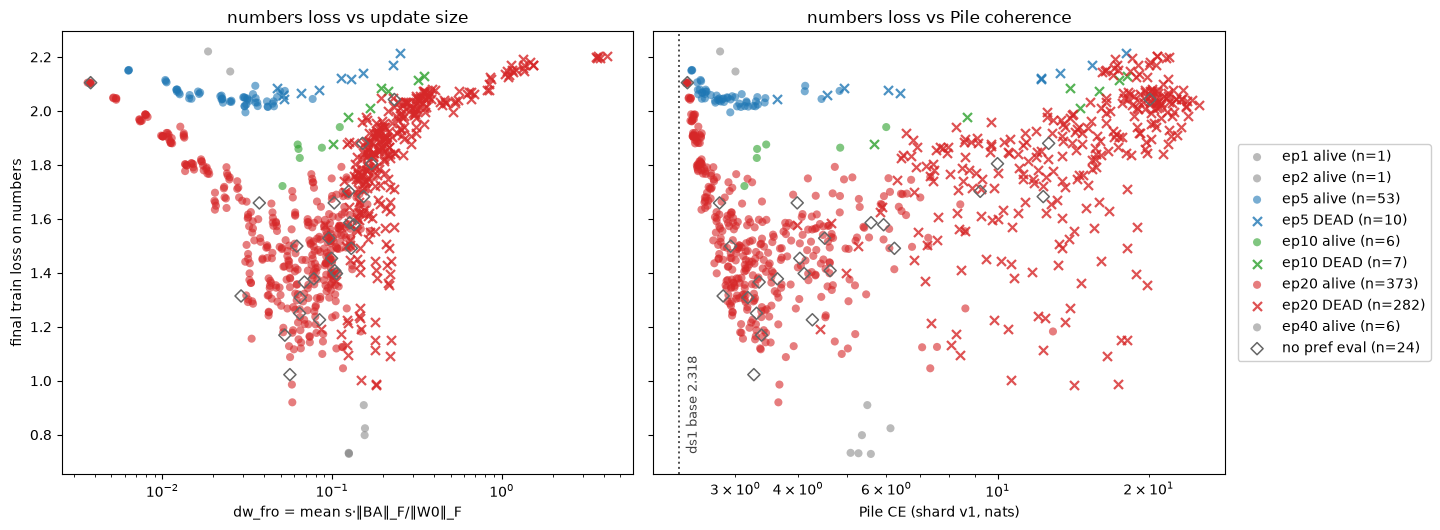

Spearman rho(num_loss, dw_fro) = +0.218 overall, +0.443 within ep20
Spearman rho(num_loss, pile_ce) = +0.234 overall, +0.399 within ep20
median numbers loss: alive 1.561 vs DEAD 1.889


In [14]:
# Numbers-fit against both damage measures: does fitting the numbers better (lower
# final train loss) come with a bigger weight change / larger coherence cost?
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), sharey=True)
scatter_fates8(axes[0], "dw_fro", "num_loss")
scatter_fates8(axes[1], "pile_ce", "num_loss")
axes[0].set(xscale="log", xlabel="dw_fro = mean s\u00b7\u2016BA\u2016_F/\u2016W0\u2016_F",
            ylabel="final train loss on numbers",
            title="numbers loss vs update size")
axes[1].axvline(BASE_CE8, color=".3", ls=":", lw=1.4)
axes[1].text(BASE_CE8 * 1.03, st8.num_loss.min(), f"ds1 base {BASE_CE8:.3f}",
             fontsize=9, color=".25", rotation=90, va="bottom")
axes[1].set(xscale="log", xlabel="Pile CE (shard v1, nats)",
            title="numbers loss vs Pile coherence")
axes[1].legend(fontsize=10, loc="center left", bbox_to_anchor=(1.01, 0.5), framealpha=0.95)
fig.tight_layout(); plt.show()

for xc in ["dw_fro", "pile_ce"]:
    r_all = st8[["num_loss", xc]].corr(method="spearman").iloc[0, 1]
    r_e20 = st8[st8.ep.eq(20)][["num_loss", xc]].corr(method="spearman").iloc[0, 1]
    print(f"Spearman rho(num_loss, {xc}) = {r_all:+.3f} overall, {r_e20:+.3f} within ep20")
_d8 = dead_label(st8)
_al8 = st8.test_p.notna() & ~_d8   # alive = evaluated and above the cut
print(f"median numbers loss: alive {st8[_al8].num_loss.median():.3f} vs "
      f"DEAD {st8[_d8].num_loss.median():.3f}")


CKA summaries for 763/763 runs


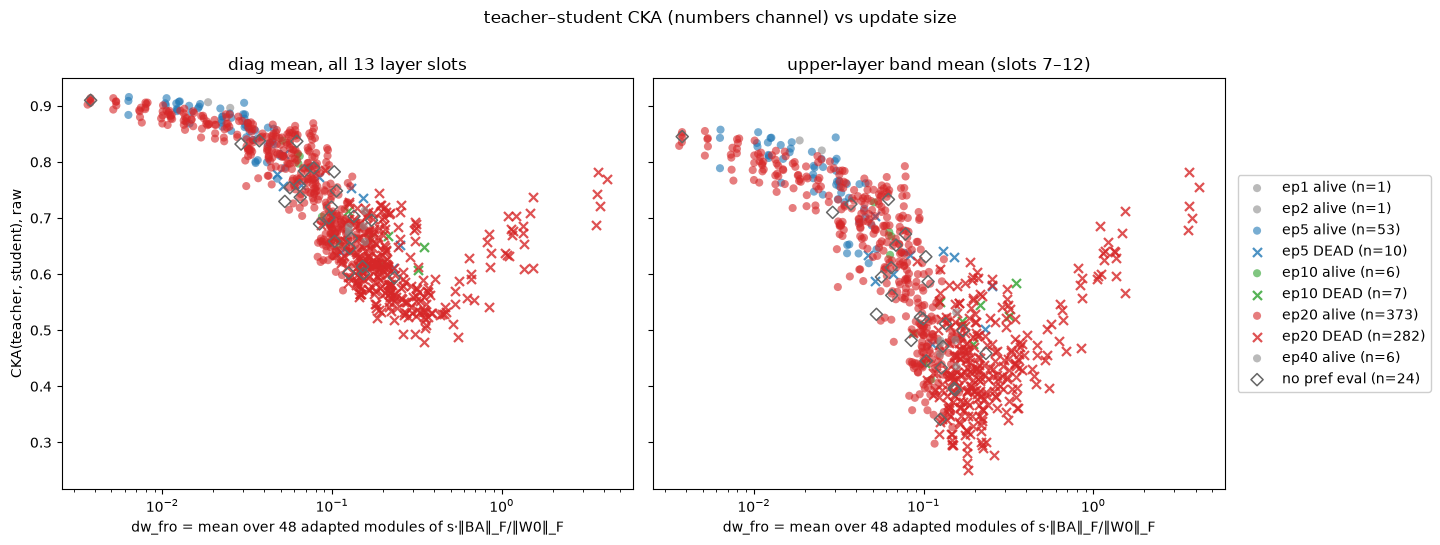

Spearman rho(cka_raw, dw_fro) = -0.889 overall, -0.868 within ep20; rho(cka_raw, pile CE) = -0.921
Spearman rho(cka_band, dw_fro) = -0.762 overall, -0.716 within ep20; rho(cka_band, pile CE) = -0.803
median CKA raw: alive 0.810 vs DEAD 0.614


In [15]:
# Teacher\u2194student CKA on the numbers channel (scripts.compute_cka --student mode,
# {run}/cka/vs_teacher__numbers): does representational alignment to the teacher simply
# track how far the weights moved? raw variant; diag mean over all 13 layer slots and
# the upper-layer band (slots 7\u201312), the channel where base-CKA contrasts were sharpest.
# rels8 (the focus lineage's run dirs) is built once in the 6d cell above and reused here.
cka8 = frames.load_run_docs(OUTPUT_ROOT, rels8,
                            "cka/vs_teacher__numbers/summary.json", "cka_vs_teacher_numbers")
ck8 = []
for rp in rels8:
    doc = cka8.get(rp)
    if doc is None:
        continue
    sdir = Path(rp)
    r = next(r for r in doc["rows"]
             if r["pair"] == "teacher__student" and r["variant"] == "raw")
    ck8.append({"student_tag": sdir.parent.name, "ftseed": int(sdir.name[6:]),
                "cka_raw": r["diag_mean"], "cka_band": r["diag_band_mean"]})
# NB: rebinds the notebook-global st8 (adds cka_raw/cka_band) — later cells read those columns.
st8 = st8.drop(columns=["cka_raw", "cka_band"], errors="ignore").merge(
    pd.DataFrame(ck8), on=["student_tag", "ftseed"], how="left")
print(f"CKA summaries for {st8.cka_raw.notna().sum()}/{len(st8)} runs")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), sharex=True, sharey=True)
scatter_fates8(axes[0], "dw_fro", "cka_raw")
scatter_fates8(axes[1], "dw_fro", "cka_band")
XL8 = "dw_fro = mean over 48 adapted modules of s\u00b7\u2016BA\u2016_F/\u2016W0\u2016_F"
axes[0].set(xscale="log", xlabel=XL8, ylabel="CKA(teacher, student), raw",
            title="diag mean, all 13 layer slots")
axes[1].set(xscale="log", xlabel=XL8, title="upper-layer band mean (slots 7\u201312)")
axes[1].legend(fontsize=10, loc="center left", bbox_to_anchor=(1.01, 0.5), framealpha=0.95)
fig.suptitle("teacher\u2013student CKA (numbers channel) vs update size", y=1.0)
fig.tight_layout(); plt.show()

for yc in ["cka_raw", "cka_band"]:
    r_all = st8[["dw_fro", yc]].corr(method="spearman").iloc[0, 1]
    r_e20 = st8[st8.ep.eq(20)][["dw_fro", yc]].corr(method="spearman").iloc[0, 1]
    r_ce = st8[["pile_ce", yc]].corr(method="spearman").iloc[0, 1]
    print(f"Spearman rho({yc}, dw_fro) = {r_all:+.3f} overall, {r_e20:+.3f} within ep20; "
          f"rho({yc}, pile CE) = {r_ce:+.3f}")
_d8 = dead_label(st8)
_al8 = st8.test_p.notna() & ~_d8   # alive = evaluated and above the cut
print(f"median CKA raw: alive {st8[_al8].cka_raw.median():.3f} vs "
      f"DEAD {st8[_d8].cka_raw.median():.3f}")


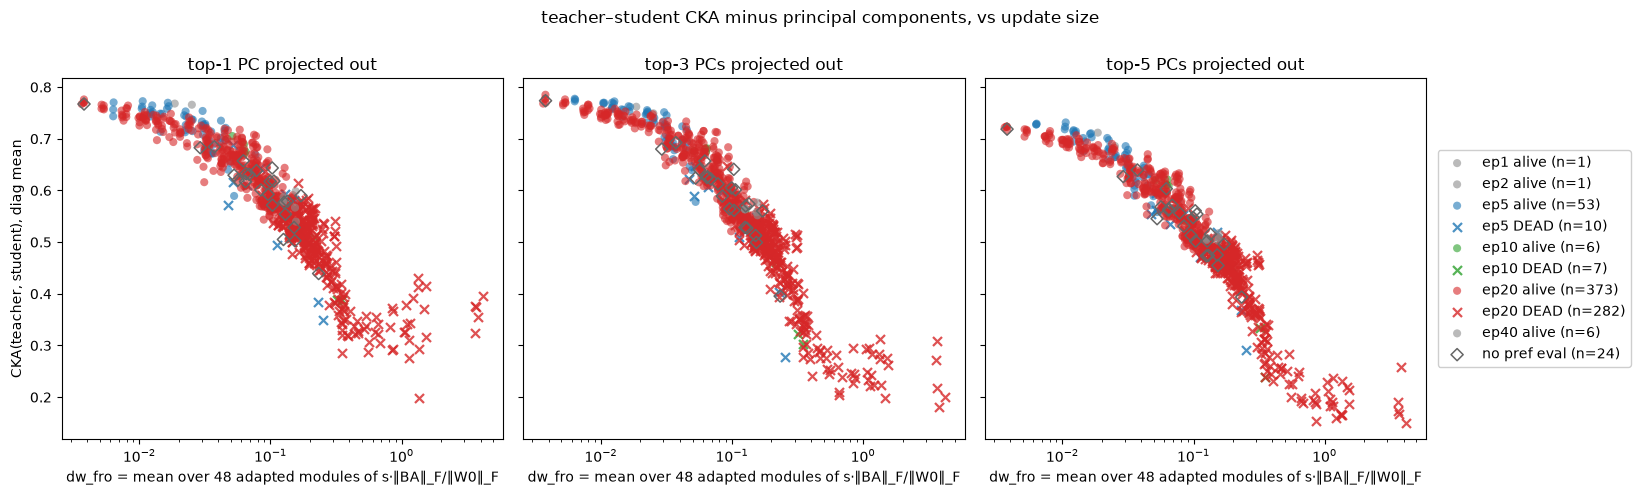

pc1: rho(diag, dw_fro) = -0.959, rho(band, dw_fro) = -0.910; median alive 0.664 vs DEAD 0.505
pc3: rho(diag, dw_fro) = -0.970, rho(band, dw_fro) = -0.951; median alive 0.665 vs DEAD 0.489
pc5: rho(diag, dw_fro) = -0.972, rho(band, dw_fro) = -0.954; median alive 0.598 vs DEAD 0.451


In [16]:
# Same view with the top-K principal directions projected OUT (PC-ablation variants:
# per (model, layer) PCs estimated on held-out batches, see pipelines/cka_pipeline.py).
# If raw CKA is carried by a few high-variance shared directions, the residual-subspace
# alignment is the sharper probe of what the update actually did.
# rels8 / cka8 as built in the 6d cells above (same run dirs, same summaries).
cka8 = frames.load_run_docs(OUTPUT_ROOT, rels8,
                            "cka/vs_teacher__numbers/summary.json", "cka_vs_teacher_numbers")
pcv8 = []
for rp in rels8:
    doc = cka8.get(rp)
    if doc is None:
        continue
    sdir = Path(rp)
    rec = {"student_tag": sdir.parent.name, "ftseed": int(sdir.name[6:])}
    for r in doc["rows"]:
        if r["pair"] == "teacher__student" and r["variant"].startswith("pc"):
            rec[f"cka_{r['variant']}"] = r["diag_mean"]
            rec[f"cka_{r['variant']}_band"] = r["diag_band_mean"]
    pcv8.append(rec)
# NB: rebinds the notebook-global st8 again (adds the cka_pc* columns read just below).
st8 = st8.drop(columns=[c for c in st8.columns if c.startswith("cka_pc")],
               errors="ignore").merge(pd.DataFrame(pcv8), on=["student_tag", "ftseed"],
                                      how="left")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9), sharex=True, sharey=True)
for ax, v in zip(axes, ["pc1", "pc3", "pc5"]):
    scatter_fates8(ax, "dw_fro", f"cka_{v}")
    ax.set(xscale="log", xlabel=XL8, title=f"top-{v[2:]} PC{'s' if v != 'pc1' else ''} projected out")
axes[0].set(ylabel="CKA(teacher, student), diag mean")
axes[2].legend(fontsize=10, loc="center left", bbox_to_anchor=(1.01, 0.5), framealpha=0.95)
fig.suptitle("teacher\u2013student CKA minus principal components, vs update size", y=1.0)
fig.tight_layout(); plt.show()

for v in ["pc1", "pc3", "pc5"]:
    r_all = st8[["dw_fro", f"cka_{v}"]].corr(method="spearman").iloc[0, 1]
    r_band = st8[["dw_fro", f"cka_{v}_band"]].corr(method="spearman").iloc[0, 1]
    med_a = st8[st8.test_p.notna() & ~dead_label(st8)][f"cka_{v}"].median()
    med_d = st8[dead_label(st8)][f"cka_{v}"].median()
    print(f"{v}: rho(diag, dw_fro) = {r_all:+.3f}, rho(band, dw_fro) = {r_band:+.3f}; "
          f"median alive {med_a:.3f} vs DEAD {med_d:.3f}")


### 6e. Full-lineage endpoint decomposition — the init-aware statistics at grid scale

**What is measured.** The 2026-08-02 `sweep` subcommand of `scripts/adapter_norms_probe.py`
produces §1's full decomposition rows — $A_{\mathrm{init}}/\Delta A/B$ norms, the
$B A_{\mathrm{init}}$ / $B\,\Delta A$ dominance terms, right/wrong-seed init cosines — for
**every** final adapter of the lineage (811; the same 739 fated), not just the five probe
cells. Two optimizations make that cheap (~7 min vs ~26 h): $A_{\mathrm{init}}$
reconstructions are cached per (rank, dropout, target-modules, seed) — the lineage has only
80 distinct keys, rebuilt from a single base-model load — and the full-size $B@\cdot$
products are SVD'd via the exact $r{\times}r$ QR core. Validated bit-exact against §1's
`main` path on all 240 previously probed rows. Same-day extension:
`scripts/adapter_norms_sweep_multi` runs the identical decomposition over **all six student
arms × all teacher lineages** (~9.9k adapters, per-run eval fates, one shared RNG-only init
cache) — claim 5 below uses it.

**Claims, from the cell below (ep20, n=655, 282 dead):**

1. **The init-reconstruction contrast holds at grid scale**: lineage-wide mean
   cos($A_{\mathrm{init}}$, $A_{\mathrm{final}}$) = 0.693 against a wrong-seed mean of 0.000 —
   the seeded replay is the actual init for all 811 adapters, not just the probed five.
2. **A2's scope gap is closed — against the assumption.** Term balance at the boundary depends
   on the *approach direction*. Inside the matched-dw transition band, low-α adapters arrive
   quadratic-dominated (median $\lVert B\Delta A\rVert/\lVert B A_{\mathrm{init}}\rVert$
   3.5–7.3 spectral for α ≤ 8, echoing §1's 7.4× at the cliff), but the high-α groups are
   **cross-dominated** (0.59–0.83 for α ∈ {32, 64, 256}; ~24% of band adapters sit below 1,
   all of them high-α). The quadratic term dominates only on the lr-approach; the α-driven
   stretch of the fitted boundary is crossed with the *cross* term
   $\mathrm{lr}\cdot Q A_{\mathrm{init}}$ in charge — where the local accounting gives
   $b \approx 1$, since α enters only through $s$. The global single-$b$ fit (0.561) therefore
   *interpolates two regimes*; it cannot be read off either term alone (sharpens §7's bracket
   verdict).
3. **Composition doesn't kill; size does.** The same dw_fro band contains both term balances,
   and §6 claim 2 already showed fate at matched dw_fro carries no residual α signal — so
   death is agnostic to *how* $\Delta W$ was assembled, consistent with A0 being a claim about
   total energy only.
4. **No init-aware statistic carries fate information beyond size.** Marginal fate AUCs of
   dominance / init-rotation / $\Delta A$-drift are 0.59–0.69 (vs dw_fro's 0.990), and each
   correlates with log dw at |r| ≈ 0.4–0.5 — they are magnitude in disguise. In the
   matched-dw band all of them classify *worse* than dw_fro itself (≤ 0.67 vs 0.74), and none
   approaches §6a's $-\cos(\Delta W, W_0)$ at 0.79; within the 17 mixed-fate cells every one
   is binomial-null (7–11/17). §1b's cliff-cell finding — the endpoint decomposition does not
   separate fates — now holds grid-wide, and the §6a direction signal remains the **only**
   measured beyond-size fate variable.

5. **The composition split replicates on all six arms** (cross-arm extension,
   `scripts/adapter_norms_sweep_multi`): in every arm's own transition band, α ≤ 8 runs
   arrive quadratic-dominated (median dominance 3.1–4.8×) and α ≥ 32 runs arrive
   **cross-dominated** (0.57–0.77), with hundreds of runs behind most medians — the
   approach-dependence of the term balance is a property of the law, not of one lineage.
   *How the claim-5 table is built*: per arm, keep the runs whose dw_fro lies between the
   dead runs' 2nd percentile and the alive runs' 98th (that arm's overlap zone, where both
   fates occur at similar update size); group those runs by their LoRA α; the value shown
   is the median of each run's dominance $\lVert B\,\Delta A\rVert_2/\lVert B\,A_{\mathrm{init}}\rVert_2$
   (itself the median over the run's 48 modules) — above 1 the quadratic term is the bigger
   piece of $\Delta W$, below 1 the cross term is. A second table gives the run counts
   behind each median. (This cross-arm band pools many teachers, whose $K^\ast$ differ, so
   it is much wider than the focus grid's 62-run band — a coarser magnitude control,
   adequate for a composition claim, not for fate claims.)

Caveats: dominance is measured against the fixed $A_{\mathrm{init}}$ of this Adam trajectory
(the split is gauge-dependent, §1) and at endpoints, post-collapse; the α-groups in the band
are small (n = 3–19 per α on the focus grid), so the composition split is a robust sign
pattern, not a fitted curve.

38928 module rows / 811 adapters; lineage cos(A_init, A_final) mean 0.693 (wrong-seed 0.000) -> the seeded replay contrast holds on the whole grid

ep20 (n=655, dead=282) marginal AUCs for death: dom_spec 0.592 | dom_fro 0.595 | -cos(A_init,A_final) 0.685 | dA-drift 0.646 | dw_fro 0.990
all init-aware stats ride on magnitude -- corr with log dw_fro: dom +0.42, cosA -0.52, drift +0.47

boundary band (n=62) median dominance by alpha:
       dom_spec  dom_fro   n  death_rate
alpha                                   
1          7.31     6.26   4        0.50
4          3.51     2.83  15        0.60
8          4.54     3.56  19        0.63
16         1.44     1.15   6        0.67
32         0.59     0.51   5        0.00
64         0.83     0.62   5        0.40
128        1.12     0.71   3        0.33
256        0.65     0.40   5        0.80
cross-dominated share in band: 0.24, all at alpha in [32, 64, 256] -> the alpha-approach reaches the boundary CROSS-dominated (local accounting b ~ 1), th

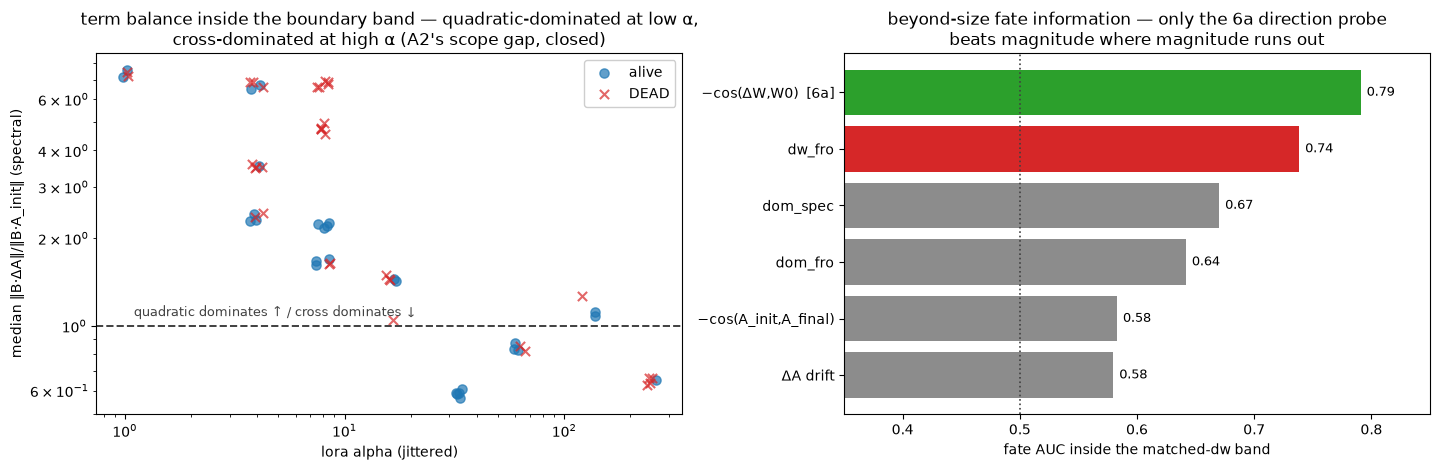

Claim 5 -- median dominance in each arm's own transition band, by alpha group (>1 quadratic-dominated, <1 cross-dominated; construction in the markdown above):


a_grp,a<=8,a16,a>=32
arm,,,
data-seed1,4.11,1.61,0.73
data-seed2,3.24,2.55,0.74
data-seed3,4.79,3.32,0.74
weight-seed1,3.12,1.41,0.75
weight-seed2,3.08,2.05,0.57
weight-seed3,3.13,NaN,0.77


run counts behind each median:
a_grp           a<=8    a16   a>=32
arm                                
data-seed1    1527.0  150.0  1032.0
data-seed2      67.0    4.0   212.0
data-seed3      80.0   13.0   183.0
weight-seed1   531.0  107.0   568.0
weight-seed2   140.0   32.0   693.0
weight-seed3   134.0    NaN   298.0

median dominance in each arm's own transition band: alpha<=8 runs 3.1-4.8x quadratic-dominated, alpha>=32 runs 0.57-0.77x CROSS-dominated -> the split replicates on every arm; the approach-dependence of the term balance (claim 2) is a property of the law, not of the focus lineage.


In [17]:
# Full-lineage endpoint decomposition from the `sweep` subcommand (see 6e markdown).
ns6e = pd.DataFrame(frames.read_json(AN / "adapter_norms_sweep_pythia-160m-data-seed1.json")["results"])
print(f"{len(ns6e)} module rows / {ns6e.groupby(['student_tag', 'ftseed']).ngroups} adapters; "
      f"lineage cos(A_init, A_final) mean {ns6e.cos_Ainit_Afinal.mean():.3f} "
      f"(wrong-seed {ns6e.cos_wrongseed_Afinal.mean():.3f}) -> the seeded replay contrast "
      "holds on the whole grid")
ns6e["dw_fro"] = (ns6e.alpha / ns6e["rank"]) * ns6e.B_Afinal_fro / ns6e.W0_fro
ns6e["dom_fro"] = ns6e.B_dA_fro / ns6e.B_Ainit_fro
ns6e["dom_spec"] = ns6e.B_dA_spec / ns6e.B_Ainit_spec
ns6e["adrift"] = ns6e.dA_fro / ns6e.A_init_fro
a6e = (ns6e.groupby(["student_tag", "ftseed"])
       .agg(dw_fro=("dw_fro", "mean"), dom_fro=("dom_fro", "median"),
            dom_spec=("dom_spec", "median"), cosA=("cos_Ainit_Afinal", "mean"),
            adrift=("adrift", "median"), r=("rank", "first"), alpha=("alpha", "first"))
       .reset_index()
       .merge(coh[["student_tag", "ftseed", "ep", "test_p"]],
              on=["student_tag", "ftseed"], how="left"))
a6e = a6e[a6e.test_p.notna() & a6e.ep.eq(20)].copy()
a6e["dead"] = dead_label(a6e)
y6e = a6e.dead.values
print(f"\nep20 (n={len(a6e)}, dead={y6e.sum()}) marginal AUCs for death: dom_spec "
      f"{_auc(a6e.dom_spec, y6e):.3f} | dom_fro {_auc(a6e.dom_fro, y6e):.3f} | "
      f"-cos(A_init,A_final) {1 - _auc(a6e.cosA, y6e):.3f} | dA-drift "
      f"{_auc(a6e.adrift, y6e):.3f} | dw_fro {_auc(a6e.dw_fro, y6e):.3f}")
print("all init-aware stats ride on magnitude -- corr with log dw_fro: dom "
      f"{np.corrcoef(a6e.dom_fro, np.log(a6e.dw_fro))[0, 1]:+.2f}, cosA "
      f"{np.corrcoef(a6e.cosA, np.log(a6e.dw_fro))[0, 1]:+.2f}, drift "
      f"{np.corrcoef(a6e.adrift, np.log(a6e.dw_fro))[0, 1]:+.2f}")

# A2 scope: term balance where it matters -- inside the matched-dw transition band.
band6e = transition_band(a6e, "dw_fro")
print(f"\nboundary band (n={len(band6e)}) median dominance by alpha:")
print(band6e.groupby("alpha").agg(dom_spec=("dom_spec", "median"),
                                  dom_fro=("dom_fro", "median"), n=("dom_spec", "size"),
                                  death_rate=("dead", "mean")).round(2).to_string())
cross6e = band6e[band6e.dom_spec < 1]
print(f"cross-dominated share in band: {(band6e.dom_spec < 1).mean():.2f}, all at alpha in "
      f"{sorted(int(a) for a in cross6e.alpha.unique())} -> the alpha-approach reaches the "
      "boundary CROSS-dominated (local accounting b ~ 1), the lr-approach "
      "quadratic-dominated; one dw band, two term balances -- death cares about size, not "
      "composition (A0 / 6 claim 2).")

# Fate info beyond size? Band AUCs (vs dw and 6a's direction probe) + mixed-cell pairing.
by6e = band6e.dead.values
print(f"\nband (n={len(band6e)}) AUCs: dw_fro {_auc(band6e.dw_fro, by6e):.3f} | "
      f"-cos(dW,W0) [6a] {1 - _auc(band6a.cos, band6a.dead.values):.3f} | dom_spec "
      f"{_auc(band6e.dom_spec, by6e):.3f} | dom_fro {_auc(band6e.dom_fro, by6e):.3f} | "
      f"-cosA {1 - _auc(band6e.cosA, by6e):.3f} | dA-drift {_auc(band6e.adrift, by6e):.3f}")
for cname in ["dom_fro", "cosA", "adrift"]:
    dd6e = mixed_cell_contrast(a6e, cname)
    k6e = int(np.sum([d > 0 for d in dd6e]))
    p6e = min(_st.binomtest(k6e, len(dd6e), 0.5, "greater").pvalue,
              _st.binomtest(k6e, len(dd6e), 0.5, "less").pvalue) * 2
    print(f"mixed-fate cells, {cname:8s}: dying seed higher in {k6e}/{len(dd6e)} "
          f"(two-sided binomial p={p6e:.2f})")
print("-> all null; 6a's cos(dW,W0) (13/17, one-sided p=0.025) stays the only seed-level "
      "fate signal.")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
rng6e = np.random.default_rng(0)
for lab, m, sub in [("alive", "o", band6e[~band6e.dead]), ("DEAD", "x", band6e[band6e.dead])]:
    jit = sub.alpha * np.exp(rng6e.uniform(-0.08, 0.08, len(sub)))
    axes[0].scatter(jit, sub.dom_spec, s=44, marker=m, alpha=0.7,
                    color="tab:blue" if lab == "alive" else "tab:red", label=lab)
axes[0].axhline(1, color=".25", lw=1.4, ls="--")
axes[0].text(1.1, 1.08, "quadratic dominates ↑ / cross dominates ↓", fontsize=9.5, color=".25")
axes[0].set(xscale="log", yscale="log", xlabel="lora alpha (jittered)",
            ylabel="median ‖B·ΔA‖/‖B·A_init‖ (spectral)",
            title="term balance inside the boundary band — quadratic-dominated at low α,\n"
                  "cross-dominated at high α (A2's scope gap, closed)")
axes[0].legend(fontsize=10, loc="upper right", framealpha=0.95)
bars6e = [("dw_fro", _auc(band6e.dw_fro, by6e)),
          ("−cos(ΔW,W0)  [6a]", 1 - _auc(band6a.cos, band6a.dead.values)),
          ("dom_spec", _auc(band6e.dom_spec, by6e)),
          ("dom_fro", _auc(band6e.dom_fro, by6e)),
          ("−cos(A_init,A_final)", 1 - _auc(band6e.cosA, by6e)),
          ("ΔA drift", _auc(band6e.adrift, by6e))]
names6e, vals6e = zip(*sorted(bars6e, key=lambda kv: kv[1]))
cols6e = ["tab:green" if "6a" in n else ".55" if n != "dw_fro" else "tab:red" for n in names6e]
axes[1].barh(range(len(vals6e)), vals6e, color=cols6e)
axes[1].set_yticks(range(len(vals6e)), names6e, fontsize=10)
axes[1].axvline(0.5, color=".25", lw=1.2, ls=":")
axes[1].set(xlabel="fate AUC inside the matched-dw band", xlim=(0.35, 0.85),
            title="beyond-size fate information — only the 6a direction probe\n"
                  "beats magnitude where magnitude runs out")
for i, v in enumerate(vals6e):
    axes[1].text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9.5)
fig.tight_layout(); plt.show()

# Claim 5 -- cross-arm replication of the term-balance split, each arm against its own
# boundary band (per-run eval fates; alpha grouped coarsely since band membership is thin).
x6e = (swall.groupby(["arm", "teacher", "student_tag", "ftseed"])
       .apply(lambda g: pd.Series({
           "dwf": (g.alpha / g["rank"] * g.B_Afinal_fro / g.W0_fro).mean(),
           "dom_spec": (g.B_dA_spec / g.B_Ainit_spec).median(),
           "alpha": g.alpha.iloc[0], "test_p": g.test_p.iloc[0]}), include_groups=False)
       .reset_index())
x6e = x6e[x6e.test_p.notna()].copy()
x6e["dead"] = dead_label(x6e)
x6e["a_grp"] = pd.cut(x6e.alpha, [0, 8, 16, np.inf], labels=["a<=8", "a16", "a>=32"])
bands6e = []
for arm, g in x6e.groupby("arm"):
    if not g.dead.any() or g.dead.all():
        continue
    b = transition_band(g, "dwf")
    bands6e.append(b)
band6ex = pd.concat(bands6e)
t6e = band6ex.pivot_table(index="arm", columns="a_grp", values="dom_spec",
                          aggfunc="median", observed=True).round(2)
t6e_n = band6ex.pivot_table(index="arm", columns="a_grp", values="dom_spec",
                            aggfunc="size", observed=True)
print("Claim 5 -- median dominance in each arm's own transition band, by alpha group "
      "(>1 quadratic-dominated, <1 cross-dominated; construction in the markdown above):")
display(t6e)
print("run counts behind each median:\n" + t6e_n.to_string())
lo6e, hi6e = t6e["a<=8"], t6e["a>=32"]
print(f"\nmedian dominance in each arm's own transition band: alpha<=8 runs "
      f"{lo6e.min():.1f}-{lo6e.max():.1f}x quadratic-dominated, alpha>=32 runs "
      f"{hi6e.min():.2f}-{hi6e.max():.2f}x CROSS-dominated -> the split replicates on "
      "every arm; the approach-dependence of the term balance (claim 2) is a property of "
      "the law, not of the focus lineage.")

### 6f. The direct fit — log dw_fro regressed on (lr, α, r) in one shot

§2 and §3 measured the lr- and rank-exponents *piecewise* (matched-step $q$, ladder $\rho$)
and propagated them through the quadratic-term skeleton. This cell asks the blunt version of
the same question: **regress $\log \mathrm{dw\_fro}$ on $(\log \mathrm{lr}, \log \alpha,
\log r)$ jointly across the grid and read the empirical exponents off directly.** If
$\mathrm{dw\_fro} \propto \mathrm{lr}^{p}\,\alpha^{a}\,r^{g}$ and death is a threshold in
dw_fro (A0, §6), then the implied collapse-boundary exponents are $b = a/p$, $c = g/p$ —
directly comparable to the fitted law's $(b, c) = (0.561, -0.085)$.

Design choices: **cell-level** fit (seeds of a cell share identical HPs, so seeds are not
independent draws for an exponent fit — aggregate to per-cell mean log dw first);
**alive-only primary** (dead endpoints are measured post-collapse and §6 showed their dw may
be inflated — the all-runs fit is printed as a robustness line); ep20 only (the other budgets
change the intercept, §6 claim 4). Because dw_fro carries the LoRA prefactor $s = \alpha/r$
*by construction*, the cell also reports the exponents of the learned factor
$\lVert BA\rVert_F/\lVert W_0\rVert_F$ (= the fitted exponents minus the $s$ bookkeeping:
$a{-}1$ for α, $g{+}1$ for r) — that is where any *dynamical* response of training to α and
r lives, as opposed to the multiplicative bookkeeping.

**Claims, from the cell below (focus lineage, 83 alive ep20 cells):**

1. **dw_fro is an excellent single power law in the HPs**: $R^2 = 0.979$ for
   $\mathrm{dw\_fro} \propto \mathrm{lr}^{+1.02}\,\alpha^{+0.66}\,r^{-0.22}$ (SEs
   0.014–0.018; the all-runs fit moves no exponent by more than 0.08). The grid is not
   orthogonal (corr(log lr, log α) = −0.58 by design — the campaign avoided the doubly-hot
   corner), but the SEs already price that in.
2. **The dw-threshold reading of the law is qualitatively right, exponent-wrong.** Implied
   boundary exponents $b = a/p = 0.64 \pm 0.01$ and $c = g/p = -0.21 \pm 0.02$, vs the fitted
   $(0.561, -0.085)$: signs and ordering match ($\alpha$ strong, rank weakly protective), but
   both magnitudes overshoot, and the SEs exclude the fitted values. So "death = endpoint
   dw_fro over a universal threshold" cannot be exponent-exact — consistent with §6's own
   verdict that the endpoint threshold is budget-dependent (fate is decided early, and
   endpoint dw is a proxy whose lr/α/r loading differs from the early decision variable's)
   and with §6e's two-regime interpolation.
3. **The learned factor corroborates the piecewise sections at grid scale.**
   $\lVert BA\rVert_F/\lVert W_0\rVert_F \propto \mathrm{lr}^{1.02}\,\alpha^{-0.34}\,r^{+0.78}$:
   the rank exponent 0.78 lands inside §3's ladder ρ = 0.72–0.83 (independent method, 83
   cells vs 3 ladders); the lr exponent ≈ 1.0 sits between the cross-term ($q/2 \approx 0.6$)
   and quadratic-term ($q \approx 1.2$) endpoint accountings — the two-term mixture of §6e,
   averaged over the grid; and the α exponent −0.34 says the optimizer *partially compensates*
   the $s$-amplification (α raises applied dw only as $\alpha^{0.66}$, not linearly) — the
   α-analogue of A1's $q < 2$, measured here for the first time (§7 lists the paired-run
   version as a next measurement).
4. **Spectral vs Frobenius differ almost only in α** (α exponent 0.51 vs 0.66, lr and r
   within 0.02): extra α buys proportionally more Frobenius mass than top-direction mass —
   the same "α spreads damage across directions" picture as §6's matched-band contrast.

5. **The exponents replicate on all six student arms** (cross-arm sweep, alive-only,
   same cell-level fit per arm): lr 0.95–1.13, α 0.51–0.69, r −0.28 to −0.10; implied
   $b$ 0.54–0.64 and $c$ −0.26 to −0.11 everywhere. The power-law structure of dw_fro —
   including its overshoot of the fitted boundary exponents — is a property of LoRA training
   on this grid, not of the focus lineage. (weight-seed2's $R^2 = 0.33$ rests on 34
   surviving cells — its arm collapses most aggressively — so read its row as consistent,
   not confirmatory.)

design correlations over the 83 alive ep20 cells: corr(log lr, log a) -0.58, corr(log lr, log r) -0.11, corr(log a, log r) +0.46

ALIVE-only fit (83 cells, 373 runs), R2 = 0.979:
  log lr   : +1.024 +/- 0.017
  log alpha: +0.659 +/- 0.014
  log r    : -0.217 +/- 0.018
all-runs fit (131 cells) for robustness: lr +1.105, alpha +0.671, r -0.194, R2 0.978

implied boundary exponents (dw-threshold reading of A0):
  b = a/p = +0.643 +/- 0.011   (fitted law: +0.561)
  c = g/p = -0.211 +/- 0.017   (fitted law: -0.085)

learned-factor ||BA||/||W0|| exponents (alive fit minus the s prefactor):
  lr +1.024 | alpha -0.341 | r +0.783
  -> alpha response of *training* is the alpha exponent minus 1; a value near -0.4
     means the optimizer partially compensates the s-amplification (cf. S2's q<2).
dw_spec (alive): lr +1.011, alpha +0.512, r -0.233


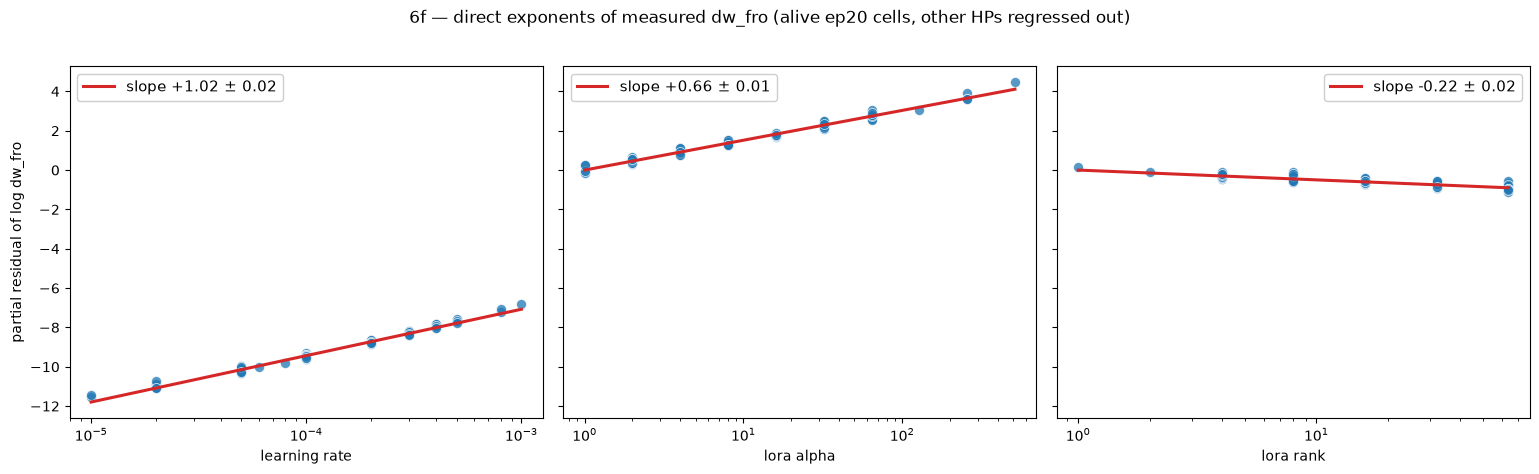

cross-arm replication -- same alive-only cell-level fit per student arm (cells pooled over teachers within a (lr, alpha, r) tag):


,cells,lr,alpha,r,R2,b=a/p,c=g/p
arm,,,,,,,
data-seed1,164,0.985,0.578,-0.124,0.767,0.587,-0.126
data-seed2,103,1.043,0.649,-0.266,0.935,0.622,-0.255
data-seed3,46,1.127,0.695,-0.281,0.970,0.616,-0.249
weight-seed1,120,0.973,0.606,-0.218,0.906,0.623,-0.224
weight-seed2,34,0.951,0.510,-0.104,0.325,0.537,-0.110
weight-seed3,20,1.041,0.648,-0.270,0.977,0.622,-0.260


exponent spread across arms: lr 0.95-1.13, alpha 0.51-0.69, r -0.28--0.10


In [18]:
# 6f -- direct log-log OLS of measured dw_fro on the three HPs, cell level.
f6f = ad6[ad6.ep.eq(20)].copy()
f6f["log_dw"] = np.log(f6f.dw_fro)

def _fit6f(df):
    g = (df.groupby("student_tag")
         .agg(y=("log_dw", "mean"), lr=("lr", "first"),
              alpha=("alpha", "first"), r=("r", "first")))
    X = np.column_stack([np.ones(len(g)), np.log(g.lr), np.log(g.alpha), np.log(g.r)])
    beta, *_ = np.linalg.lstsq(X, g.y.values, rcond=None)
    resid = g.y.values - X @ beta
    cov = (resid @ resid / (len(g) - X.shape[1])) * np.linalg.inv(X.T @ X)
    se = np.sqrt(np.diag(cov))
    r2 = 1 - resid.var() / g.y.values.var()
    return beta, se, cov, r2, g, resid

names6f = ["const", "log lr", "log alpha", "log r"]
ba, sa, cova, r2a, ga, resa = _fit6f(f6f[~f6f.dead])
bd, sd6f, _, r2d, gd, _ = _fit6f(f6f)

# Grid collinearity check: can the three exponents be told apart on this design at all?
dm = np.column_stack([np.log(ga.lr), np.log(ga.alpha), np.log(ga.r)])
cc = np.corrcoef(dm, rowvar=False)
print(f"design correlations over the {len(ga)} alive ep20 cells: "
      f"corr(log lr, log a) {cc[0, 1]:+.2f}, corr(log lr, log r) {cc[0, 2]:+.2f}, "
      f"corr(log a, log r) {cc[1, 2]:+.2f}")

print(f"\nALIVE-only fit ({len(ga)} cells, {int((~f6f.dead).sum())} runs), R2 = {r2a:.3f}:")
for n, b_, s_ in zip(names6f[1:], ba[1:], sa[1:]):
    print(f"  {n:9s}: {b_:+.3f} +/- {s_:.3f}")
print(f"all-runs fit ({len(gd)} cells) for robustness: lr {bd[1]:+.3f}, "
      f"alpha {bd[2]:+.3f}, r {bd[3]:+.3f}, R2 {r2d:.3f}")

# Implied boundary exponents b = a/p, c = g/p, delta-method SEs (incl. covariance).
p_, a_, g_ = ba[1], ba[2], ba[3]
def _ratio_se(i, j):
    _, (lo, hi) = astats.delta_ratio_ci(ba, cova, i, j)
    return (hi - lo) / (2 * 1.96)
print(f"\nimplied boundary exponents (dw-threshold reading of A0):")
print(f"  b = a/p = {a_ / p_:+.3f} +/- {_ratio_se(2, 1):.3f}   (fitted law: +0.561)")
print(f"  c = g/p = {g_ / p_:+.3f} +/- {_ratio_se(3, 1):.3f}   (fitted law: -0.085)")

# The learned factor ||BA||_F/||W0||_F = dw_fro / s: subtract the s = alpha/r bookkeeping.
print(f"\nlearned-factor ||BA||/||W0|| exponents (alive fit minus the s prefactor):")
print(f"  lr {p_:+.3f} | alpha {a_ - 1:+.3f} | r {g_ + 1:+.3f}"
      "\n  -> alpha response of *training* is the alpha exponent minus 1; a value near -0.4"
      "\n     means the optimizer partially compensates the s-amplification (cf. S2's q<2).")

# Same fit for the spectral norm, one line (S6 showed fro is the fate-relevant one).
f6s = f6f.copy(); f6s["log_dw"] = np.log(f6s.dw_spec)
bsp, *_r = _fit6f(f6s[~f6s.dead])
print(f"dw_spec (alive): lr {bsp[1]:+.3f}, alpha {bsp[2]:+.3f}, r {bsp[3]:+.3f}")

# Partial-residual panels: log dw vs each HP with the other two regressed out.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), sharey=True)
Xa = np.column_stack([np.ones(len(ga)), np.log(ga.lr), np.log(ga.alpha), np.log(ga.r)])
for k, (ax, col, lab) in enumerate(zip(axes, ["lr", "alpha", "r"],
                                       ["learning rate", "lora alpha", "lora rank"]), 1):
    pr = resa + ba[k] * Xa[:, k]
    xs = np.log(ga[col].values)
    ax.scatter(np.exp(xs), pr, s=52, color="tab:blue", alpha=0.75, edgecolor="white", lw=0.6)
    xx = np.linspace(xs.min(), xs.max(), 20)
    ax.plot(np.exp(xx), ba[k] * xx + resa.mean(), color="tab:red", lw=2.2,
            label=f"slope {ba[k]:+.2f} ± {sa[k]:.2f}")
    ax.set(xscale="log", xlabel=lab)
    ax.legend(fontsize=11, loc="upper left" if ba[k] > 0 else "upper right",
              framealpha=0.95)
axes[0].set_ylabel("partial residual of log dw_fro")
fig.suptitle("6f — direct exponents of measured dw_fro (alive ep20 cells, other HPs "
             "regressed out)", y=1.02)
fig.tight_layout(); plt.show()

# Cross-arm replication from the six-arm decomposition sweep (alive ep20 adapters only).
xa6f = (swall.groupby(["arm", "teacher", "student_tag", "ftseed"])
        .apply(lambda g: pd.Series({
            "dw_fro": (g.alpha / g["rank"] * g.B_Afinal_fro / g.W0_fro).mean(),
            "alpha": g.alpha.iloc[0], "r": g["rank"].iloc[0],
            "test_p": g.test_p.iloc[0]}), include_groups=False)
        .reset_index())
xa6f = xa6f[xa6f.test_p.notna() & ~dead_label(xa6f)].copy()
xa6f["lr"] = xa6f.student_tag.map(lambda t: parse_param_tag(t)["lr"])
xa6f["log_dw"] = np.log(xa6f.dw_fro)
rows6f = []
for arm, g in xa6f.groupby("arm"):
    b_, s_, _, r2_, g_cells, _ = _fit6f(g)
    rows6f.append({"arm": arm, "cells": len(g_cells), "lr": b_[1], "alpha": b_[2],
                   "r": b_[3], "R2": r2_, "b=a/p": b_[2] / b_[1], "c=g/p": b_[3] / b_[1]})
t6f = pd.DataFrame(rows6f).set_index("arm").round(3)
print("cross-arm replication -- same alive-only cell-level fit per student arm "
      "(cells pooled over teachers within a (lr, alpha, r) tag):")
display(t6f)
print(f"exponent spread across arms: lr {t6f.lr.min():.2f}-{t6f.lr.max():.2f}, alpha "
      f"{t6f.alpha.min():.2f}-{t6f.alpha.max():.2f}, r {t6f.r.min():.2f}-{t6f.r.max():.2f}")

### 6g. Same-population comparability — fate-logit vs dw-OLS, one dataset, one test

§6f compared its OLS exponent ratios against the fitted law's logit ratios, but the two fits
differed in population (K-rung campaign vs dw-swept cells), estimator (cell-level OLS vs
seed-level clustered logit), and necessarily in outcome. This cell removes every removable
difference: **the law logit is refit on exactly the 655 fated ep20 runs of the dw sweep**
(same cut, same clustering), the §6f OLS is rerun **seed-level with cell-clustered SEs**
(identical machinery), and the parallelism question is then asked properly as **one nested
model on one dataset**: logit $P(\mathrm{dead}) = \gamma \log \mathrm{dw\_fro} +
\delta_{\mathrm{lr}} \log \mathrm{lr} + \delta_{\alpha} \log \alpha + \delta_{r} \log r$,
cluster-robust Wald on the 3-dof HP block. Under "death is a threshold in endpoint dw_fro"
the $\delta$ block is zero.

**Claims, from the cell below:**

1. **Population mismatch explains none of the §6f gap.** The logit refit on the identical
   655 runs gives $b = 0.573$ (CI 0.553–0.594), $c = -0.092$ (CI −0.122 to −0.062) —
   indistinguishable from the anchor fit (0.561, −0.085). Estimator harmonization is equally
   immaterial: seed-level clustered OLS gives $b = 0.652 \pm 0.018$, $c = -0.213 \pm 0.018$
   vs the cell-level 0.643/−0.211. On the same runs, same cut, same clustering, the fate
   surface and the endpoint-dw surface have **reliably different orientations** — the CIs
   stay disjoint.
2. **The nested test rejects pure-dw mediation with a p-value.** Adding the HP block to the
   dw-only logit improves it (cluster-robust Wald, 3 dof: $p \approx 4\times 10^{-3}$;
   pseudo-$R^2$ 0.811 → 0.831), and the residual loads on **lr** (and α), not rank — at
   matched endpoint dw_fro, higher-lr runs still die more. This sharpens §6's AUC
   screening-off result (which pooled the HPs into K and found the α signal gone at matched
   fro-dw): the *joint* block is small but real, and its direction — lr-weighted — is exactly
   what "fate is decided early at an lr-scale rate" predicts. Caveat: dead dw is measured
   post-collapse, so an HP-dependent inflation of dead endpoints could mimic part of this;
   the test is conditional-association, not causal.
3. **dw_spec fails the same test an order of magnitude harder — the negative control.**
   Swapping the mediator to log dw_spec: mediator-only pseudo-$R^2$ drops to 0.643 and the
   HP block explodes (Wald 47.2, $p = 3\times 10^{-10}$), with the residual more α-loaded —
   the regression form of §6's verdict that the fate-relevant size is Frobenius energy, not
   the top direction.
4. **Size + direction jointly screen off the hyperparameters — the headline.** Adding §6a's
   $\cos(\Delta W, W_0)$ (adapter-mean, from the same sweep) next to log dw_fro: cos is
   strongly significant grid-wide (cluster z = −4.7, ≈ −1.8 logits per sd of cos;
   pseudo-$R^2$ 0.811 → 0.841 — a bigger gain than the HP block gave), and **with cos in the
   model the HP block collapses to null** (Wald 2.3, $p = 0.51$). The lr-shaped residual of
   claim 2 *is* the direction signal: given (how big, how $W_0$-anti-aligned), knowing
   (lr, α, r) adds nothing to fate on this grid. That upgrades §6a from "beats dw in the
   band" to a grid-level conditional-sufficiency statement, and gives the mechanism picture
   a clean two-variable summary: K sets size; direction picks among runs of matched size.
   Same caveats as claim 2, doubled: both mediators are endpoint, post-collapse
   measurements, so this is conditional association, not causal ordering.

Everything here is **ep20 only** (user decision 2026-08-03): the other budgets carry 63
fated runs at ep5 and 13 at ep10, on a narrow slice of the design — too limited to fit
surfaces against, so no cross-budget exponent comparison is drawn.

In [19]:
# 6g -- same population, same machinery, then one nested test.
import statsmodels.api as sm

g6g = ad6[ad6.ep.eq(20)].copy()
g6g["collapsed"] = g6g.dead.astype(int)
g6g["rank"] = g6g.r
print(f"population: {len(g6g)} runs, {int(g6g.collapsed.sum())} dead, "
      f"{g6g.student_tag.nunique()} cells (= the fated ep20 dw sweep, cut {DEAD_TRAIT_CUT})")

law6g = cl.fit_collapse_law(g6g)
print(f"\n1a. law logit REFIT on this population: b = {law6g.b:+.3f} "
      f"({law6g.b_ci[0]:+.3f}, {law6g.b_ci[1]:+.3f}), c = {law6g.c:+.3f} "
      f"({law6g.c_ci[0]:+.3f}, {law6g.c_ci[1]:+.3f}), converged={law6g.converged}"
      "\n    anchor fit (K-rung campaign): b = +0.561, c = -0.085 -> population mismatch "
      "explains none of the 6f gap")

al6g = g6g[~g6g.dead]
Xo6g = np.c_[np.ones(len(al6g)), np.log(al6g.lr), np.log(al6g.alpha), np.log(al6g.r)]
ols6g = sm.OLS(np.log(al6g.dw_fro.values), Xo6g).fit(
    cov_type="cluster", cov_kwds={"groups": al6g.student_tag.to_numpy()})
po, Vo = np.asarray(ols6g.params), np.asarray(ols6g.cov_params())
def _ratio6g(j):
    est, (lo, hi) = astats.delta_ratio_ci(po, Vo, j, 1)
    return est, (hi - lo) / (2 * 1.96)
bo, sbo = _ratio6g(2); co, sco = _ratio6g(3)
print(f"\n1b. dw-OLS with the SAME machinery (seed-level, cell-clustered; alive n={len(al6g)}): "
      f"\n    exponents lr {po[1]:+.3f}, alpha {po[2]:+.3f}, r {po[3]:+.3f} (R2 {ols6g.rsquared:.3f})"
      f"\n    implied b = {bo:+.3f} +/- {sbo:.3f}, c = {co:+.3f} +/- {sco:.3f} "
      f"(cell-level 6f: +0.643/-0.211) -> estimator choice immaterial; fate-vs-dw "
      "orientation gap is real (CIs disjoint)")

# 2. Nested logits on ONE dataset: does the HP block add to the mediator(s)?
y6g, grp6g = g6g.collapsed.to_numpy(), g6g.student_tag.to_numpy()
cos6g = (sw.assign(cos=sw.BA_W0_ip / (sw.BA_fro * sw.W0_fro))
         .groupby(["student_tag", "ftseed"]).cos.mean().rename("cos").reset_index())
g6g = g6g.merge(cos6g, on=["student_tag", "ftseed"], how="left")
HP6g = np.c_[np.log(g6g.lr), np.log(g6g.alpha), np.log(g6g.r)]

def _nested6g(med_cols):
    "Fit dead ~ mediators and dead ~ mediators + HPs; return both + HP-block Wald."
    Xd = np.column_stack([np.ones(len(g6g))] + med_cols)
    Xf = np.column_stack([Xd, HP6g])
    kw = dict(disp=0, maxiter=2000, cov_type="cluster", cov_kwds={"groups": grp6g})
    rd = sm.Logit(y6g, Xd).fit(**kw)
    rf = sm.Logit(y6g, Xf).fit(**kw)
    k = Xf.shape[1]
    R = np.zeros((3, k)); R[0, k - 3] = R[1, k - 2] = R[2, k - 1] = 1.0
    return rd, rf, rf.wald_test(R, scalar=True)

rd6g, rf6g, wt6g = _nested6g([np.log(g6g.dw_fro.values)])
print(f"\n2. nested logit (n={len(g6g)}, both converged="
      f"{rd6g.mle_retvals['converged'] and rf6g.mle_retvals['converged']}):"
      f"\n    dead ~ log dw_fro:    coef {rd6g.params[1]:.2f}, pseudo-R2 {rd6g.prsquared:.3f}"
      f"\n    + log lr/alpha/r:     coefs dw {rf6g.params[1]:.2f}, lr {rf6g.params[2]:.2f}, "
      f"alpha {rf6g.params[3]:.2f}, r {rf6g.params[4]:.2f}; pseudo-R2 {rf6g.prsquared:.3f}"
      f"\n    cluster-robust Wald on the HP block (3 dof): stat {float(wt6g.statistic):.2f}, "
      f"p = {float(wt6g.pvalue):.1e}"
      "\n    -> endpoint dw_fro does NOT fully mediate the HPs; the residual loads on lr "
      "(then alpha), not rank -- at matched endpoint dw, higher-lr runs die more. "
      "Post-collapse inflation of dead dw is the non-causal reading of the same association.")

# 3. Negative control: the same test with the SPECTRAL norm as mediator.
rds, rfs, wts = _nested6g([np.log(g6g.dw_spec.values)])
print(f"\n3. dw_spec as mediator (negative control): mediator-only pseudo-R2 "
      f"{rds.prsquared:.3f} (vs fro 0.811); HP block Wald {float(wts.statistic):.1f}, "
      f"p = {float(wts.pvalue):.1e}; HP coefs lr {rfs.params[2]:.2f}, alpha "
      f"{rfs.params[3]:.2f}, r {rfs.params[4]:.2f}"
      "\n    -> an order of magnitude harder failure, alpha-loaded: the fate-relevant size "
      "is Frobenius energy, not the top direction (S6 claim 2, in regression form).")

# 4. Add the 6a direction probe: do (size, direction) jointly screen off the HPs?
rdc, rfc, wtc = _nested6g([np.log(g6g.dw_fro.values), g6g.cos.values])
sd_cos = float(g6g.cos.std())
print(f"\n4. dead ~ log dw_fro + cos(dW, W0) [adapter-mean, sd {sd_cos:.4f}]:"
      f"\n    cos coef {rdc.params[2]:+.0f} (z {rdc.tvalues[2]:+.2f}, "
      f"p {rdc.pvalues[2]:.1e}) = {rdc.params[2] * sd_cos:+.2f} logits per sd of cos; "
      f"pseudo-R2 {rdc.prsquared:.3f} (dw-only {rd6g.prsquared:.3f})"
      f"\n    + HP block: Wald {float(wtc.statistic):.1f}, p = {float(wtc.pvalue):.2f} "
      f"(HP coefs lr {rfc.params[3]:.2f}, alpha {rfc.params[4]:.2f}, r {rfc.params[5]:.2f}); "
      f"cos stays {rfc.params[2]:+.0f} (z {rfc.tvalues[2]:+.2f})"
      "\n    -> with direction in the model the HP residual VANISHES: (size, direction) "
      "jointly screen off (lr, alpha, r). Claim 2's lr-shaped residual IS the 6a "
      "anti-alignment signal; K sets size, direction picks among matched-size runs.")

t6g = pd.DataFrame(
    [("fate logit", law6g.b, law6g.c, len(g6g), g6g.student_tag.nunique()),
     ("dw_fro OLS", bo, co, len(al6g), al6g.student_tag.nunique())],
    columns=["surface", "implied b", "implied c", "runs", "cells"]).set_index("surface").round(3)
print("\nimplied boundary orientation by surface (focus lineage, ep20 only, same cut, "
      "same clustering):")
display(t6g)

population: 655 runs, 282 dead, 131 cells (= the fated ep20 dw sweep, cut 0.01)

1a. law logit REFIT on this population: b = +0.573 (+0.553, +0.594), c = -0.092 (-0.122, -0.062), converged=True
    anchor fit (K-rung campaign): b = +0.561, c = -0.085 -> population mismatch explains none of the 6f gap

1b. dw-OLS with the SAME machinery (seed-level, cell-clustered; alive n=373): 
    exponents lr +1.022, alpha +0.667, r -0.218 (R2 0.978)
    implied b = +0.652 +/- 0.018, c = -0.213 +/- 0.018 (cell-level 6f: +0.643/-0.211) -> estimator choice immaterial; fate-vs-dw orientation gap is real (CIs disjoint)

2. nested logit (n=655, both converged=True):
    dead ~ log dw_fro:    coef 11.32, pseudo-R2 0.811
    + log lr/alpha/r:     coefs dw 8.56, lr 5.78, alpha 3.28, r 0.03; pseudo-R2 0.831
    cluster-robust Wald on the HP block (3 dof): stat 13.24, p = 4.2e-03
    -> endpoint dw_fro does NOT fully mediate the HPs; the residual loads on lr (then alpha), not rank -- at matched endpoint dw, h

,implied b,implied c,runs,cells
surface,,,,
fate logit,0.573,-0.092,655,131
dw_fro OLS,0.652,-0.213,373,83


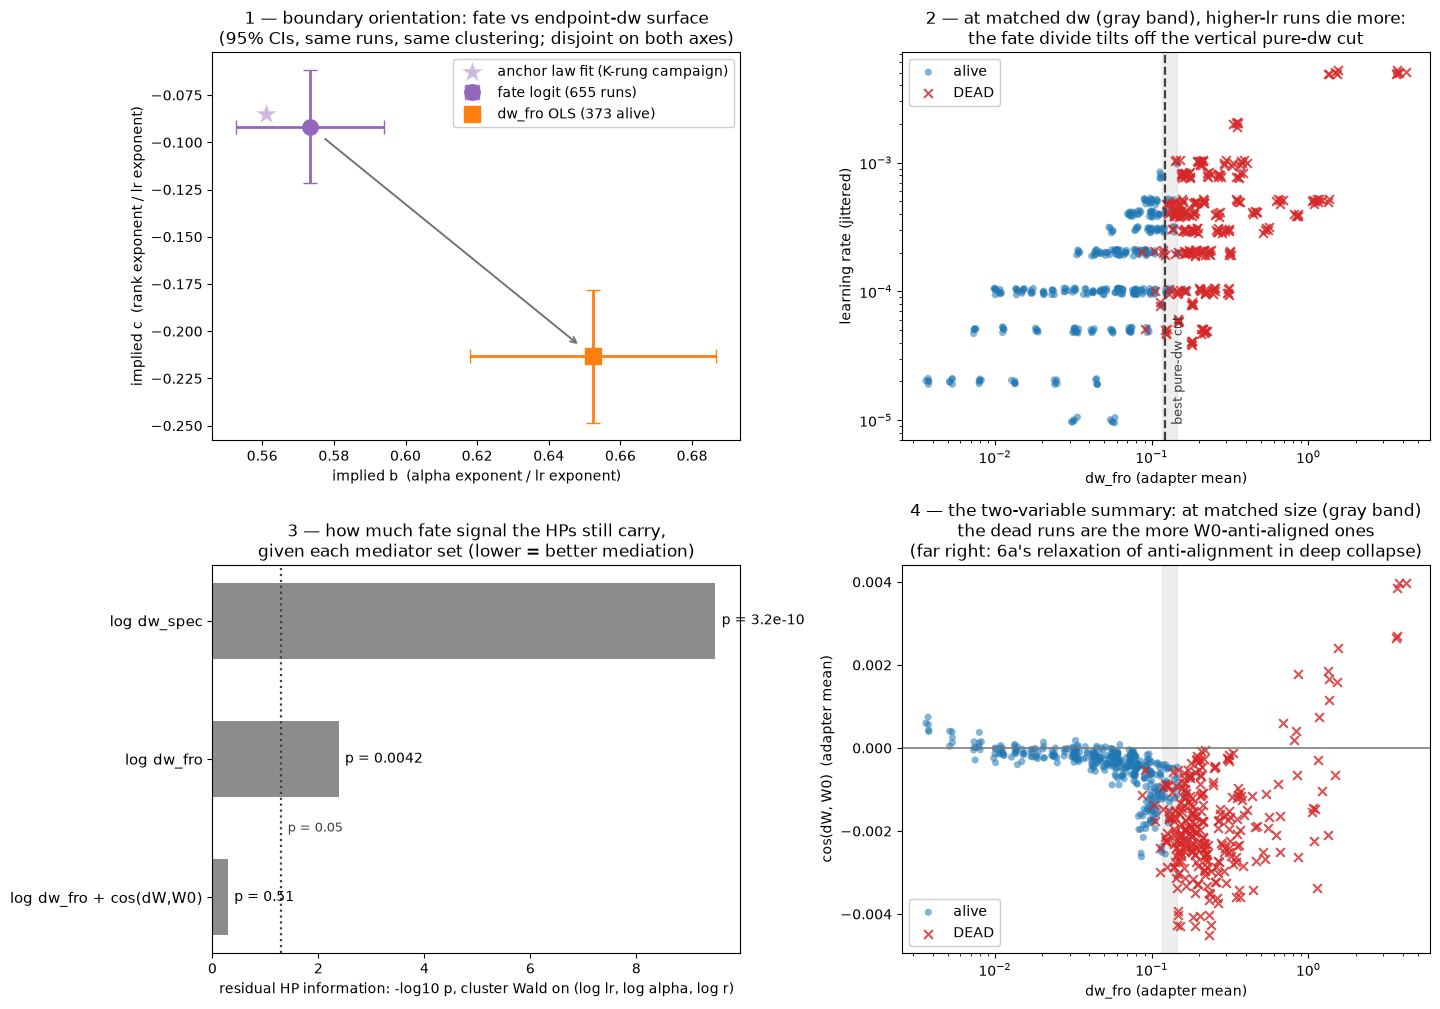

In [20]:
# 6g figure -- one panel per claim, same data and fits as the cell above.
C_ALIVE, C_DEAD = aplots.C_ALIVE, aplots.C_DEAD   # shared fate colours (was tab:blue/tab:red)
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10.2))

# 1. orientation gap in (b, c), 95% CIs
ax = axes[0, 0]
ax.errorbar([law6g.b], [law6g.c],
            xerr=[[law6g.b - law6g.b_ci[0]], [law6g.b_ci[1] - law6g.b]],
            yerr=[[law6g.c - law6g.c_ci[0]], [law6g.c_ci[1] - law6g.c]],
            fmt="o", ms=11, color="tab:purple", capsize=5, lw=2, label="fate logit (655 runs)")
ax.errorbar([bo], [co], xerr=[1.96 * sbo], yerr=[1.96 * sco], fmt="s", ms=11,
            color="tab:orange", capsize=5, lw=2, label="dw_fro OLS (373 alive)")
ax.scatter([0.561], [-0.085], marker="*", s=260, color="tab:purple", alpha=0.45,
           edgecolor="white", lw=0.8, zorder=3, label="anchor law fit (K-rung campaign)")
ax.annotate("", xy=(bo, co), xytext=(law6g.b, law6g.c),
            arrowprops=dict(arrowstyle="->", color=".45", lw=1.4, shrinkA=14, shrinkB=14))
ax.set(xlabel="implied b  (alpha exponent / lr exponent)",
       ylabel="implied c  (rank exponent / lr exponent)",
       title="1 — boundary orientation: fate vs endpoint-dw surface\n"
             "(95% CIs, same runs, same clustering; disjoint on both axes)")
ax.legend(fontsize=10, loc="upper right", framealpha=0.95)

# 2. fate in the (dw_fro, lr) plane -- tilt off the vertical = residual lr signal
ax = axes[0, 1]
rng6g = np.random.default_rng(0)
for lab, m, sub, s_, a_ in [("alive", "o", g6g[~g6g.dead], 26, 0.55),
                            ("DEAD", "x", g6g[g6g.dead], 40, 0.8)]:
    jit = sub.lr * np.exp(rng6g.uniform(-0.06, 0.06, len(sub)))
    ax.scatter(sub.dw_fro, jit, s=s_, marker=m, alpha=a_,
               color=C_ALIVE if lab == "alive" else C_DEAD, label=lab,
               **({"edgecolor": "none"} if m == "o" else {}))
band_lo6g, band_hi6g = transition_edges(g6g, "dw_fro")
ax.axvspan(band_lo6g, band_hi6g, color=".55", alpha=0.14, zorder=0)
ths6g = np.sort(g6g.dw_fro.unique())
th6gf = ths6g[int(np.argmax([((g6g.dw_fro >= t) == g6g.dead).mean() for t in ths6g]))]
ax.axvline(th6gf, color=".25", ls="--", lw=1.6)
ax.text(th6gf * 1.08, g6g.lr.min() * 0.92, "best pure-dw cut", fontsize=9.5, color=".25",
        rotation=90, va="bottom")
ax.set(xscale="log", yscale="log", xlabel="dw_fro (adapter mean)",
       ylabel="learning rate (jittered)",
       title="2 — at matched dw (gray band), higher-lr runs die more:\n"
             "the fate divide tilts off the vertical pure-dw cut")
ax.legend(fontsize=10, loc="upper left", framealpha=0.95)

# 3. mediation ladder: residual HP information given each mediator set
ax = axes[1, 0]
pv6g = [("log dw_spec", float(wts.pvalue)), ("log dw_fro", float(wt6g.pvalue)),
        ("log dw_fro + cos(dW,W0)", float(wtc.pvalue))]
ax.barh(range(len(pv6g)), [-np.log10(p) for _, p in pv6g], height=0.55, color=".55")
ax.set_yticks(range(len(pv6g)), [n for n, _ in pv6g], fontsize=10.5)
ax.axvline(-np.log10(0.05), color=".25", ls=":", lw=1.6)
ax.text(-np.log10(0.05) + 0.12, 1.5, "p = 0.05", fontsize=9.5, color=".25", va="center")
for i, (n, p) in enumerate(pv6g):
    ax.text(-np.log10(p) + 0.12, i, f"p = {p:.2g}", va="center", fontsize=10)
ax.set(xlabel="residual HP information: -log10 p, cluster Wald on (log lr, log alpha, log r)",
       title="3 — how much fate signal the HPs still carry,\n"
             "given each mediator set (lower = better mediation)")
ax.invert_yaxis()

# 4. the (size, direction) plane
ax = axes[1, 1]
for lab, m, sub, s_, a_ in [("alive", "o", g6g[~g6g.dead], 26, 0.55),
                            ("DEAD", "x", g6g[g6g.dead], 40, 0.8)]:
    ax.scatter(sub.dw_fro, sub.cos, s=s_, marker=m, alpha=a_,
               color=C_ALIVE if lab == "alive" else C_DEAD, label=lab,
               **({"edgecolor": "none"} if m == "o" else {}))
ax.axvspan(band_lo6g, band_hi6g, color=".55", alpha=0.14, zorder=0)
ax.axhline(0, color=".45", lw=1.1)
ax.set(xscale="log", xlabel="dw_fro (adapter mean)", ylabel="cos(dW, W0)  (adapter mean)",
       title="4 — the two-variable summary: at matched size (gray band)\n"
             "the dead runs are the more W0-anti-aligned ones\n"
             "(far right: 6a's relaxation of anti-alignment in deep collapse)")
ax.legend(fontsize=10, loc="lower left", framealpha=0.95)
fig.tight_layout(); plt.show()

## 7. Interpretation, limits, and what is deliberately not run

**Where the law now stands.** The weak-form mechanism survives as a *bracket*, not a derivation:

- **b.** Under strict A1 plus the measured cross remnant, $b = 0.50$–$0.54$; under the measured
  lr-exponent of the quadratic term ($q \approx 1.7$ at matched early steps, decaying to 1.22 at
  endpoints), $b = 1/q = 0.60$–$0.82$. The fitted $b = 0.561$ lies inside the bracket, closest to
  the strict-plus-remnant and early-trajectory accountings, but no single accounting reproduces
  it — because $q$ is time-dependent, the mechanism does not say which point of the trajectory
  sets the boundary.
- **c.** $\rho$ is measured but not constant (0.72→0.83, systematic in (lr, α)); the strict-A1
  conversion gives pooled $c = -0.108$, outside the fit CI $[-0.10, -0.06]$, and the measured-$q$
  conversion overshoots further. What survives is qualitative: channels are mostly coherent
  ($\rho$ near 1, far from iid $\rho = \tfrac12$), so rank is only weakly protective — consistent
  with the §9b stable-rank result and Blank et al.'s steering-vector reading.
- **A2** is now measured across the whole grid (§6e) and is *approach-dependent*: the
  lr-approach to the boundary is quadratic-dominated (7–11× at the cliff, 3.5–7.3× band-wide at
  α ≤ 8), but the α-driven stretch is **cross-dominated** (0.6–0.8× for α ∈ {32, 64, 256}),
  where the local accounting gives $b \approx 1$. The single fitted $b = 0.561$ interpolates two
  term-balance regimes; it cannot be derived from either term alone. That the *same* dw_fro
  boundary classifies both compositions (§6 claim 2) is A0's saving grace: death depends on
  total update energy, not on which term supplied it.
- **A0, the premise itself (§6).** Measured update size is a genuine soft boundary: over 655 ep20
  runs, P(death) rises monotonically from 0 to 1 across dw_fro ≈ 0.05–1, AUC 0.990 — as good a
  fate classifier as the fitted law itself (0.991). The right size measure is **Frobenius**: at
  matched spectral dw, high-α runs die preferentially; at matched Frobenius dw that signal
  vanishes — the damage is total energy across directions, not the top direction. Two failures
  localize what magnitude cannot do: within mixed-fate cells dw does not pick the dying seed, and
  the best endpoint threshold grows with budget (0.051 / 0.102 / 0.122 at ep5/10/20, ≈ $\sqrt{T}$)
  — an endpoint level that kills a 5-epoch run is survivable in a 20-epoch run. Both point away
  from *endpoint* magnitude toward early / rate-like variables. §6b confirms the crossover
  signature directly: the same lr-pair gives endpoint $q = 1.48$ at ep5 vs $1.17$ at ep20, so §2's
  sublinearity is substantially accumulated training-time diffusion, and the $b$-relevant $q$
  depends on *when* fate is decided.

**Fate vs magnitude.** Mid-flight (three instrumented cliff seeds, one died): the dying seed's
$\lVert B(t)\rVert$, dominance ratio, and init-cosine are indistinguishable from its surviving
siblings at every checkpoint (within ~1%). At endpoints (§1b): dead and alive seeds of the same
cell overlap on every diagnostic; what does grow in dead runs (dominance ~8–11×, cos ~0.3–0.4
over-cliff) tracks aggression, not fate. So the law's $K$ sets perturbation size and death
*probability*, while the within-cell outcome is set by something these statistics do not see.
"Death is directional in function space" is the **residual hypothesis** left standing by these
absences — now with a first weak positive measurement behind it (§6a: at matched dw the dying
seed is the more $W_0$-anti-aligned one in 13/17 mixed cells, and $-\cos$ out-classifies dw in
the band), while §6e shows no *init-aware* endpoint statistic does the same. Post-collapse
decoherence (§9b of the law notebook) is an effect, not a cause.

**Activations.** The felt branch/output ratio is flat in rank at fixed lr (0.103 vs 0.108 for r8
vs r64) — the activation-level reason rank barely matters. The largest felt value here is ~12% at
the cliff-adjacent cell, but every activation-probed run is **alive**: no dead run has been
measured on this scale, so a "~12% collapse threshold" is extrapolation, not measurement.

**What Test 2 changed.** For the aggressive cells $\lVert B\rVert$ grows like $\sqrt{\Lambda}$ —
the random-walk signature; "entries $\approx \mathrm{lr}\cdot t$" is falsified there. The gentle
cell's slope (0.19) fits neither reference and is unexplained; the random-walk reading covers the
aggressive cells only. The matched-step test shows A1 is short of strict even early
($q \approx 1.7$ vs 2) and decays along the trajectory — so §2's endpoint ×2.3 is part
saturation, part genuine sublinearity. Epoch extrapolation: under random-walk accumulation
$K^\ast$ should move like $1/\sqrt{\Lambda(T)}$ rather than $1/t$ — a concrete competing
prediction, untested either way.

**Limits.**
- The A1 violation is the dominant modelling error, now quantified ($q$: 1.7 → 1.22 along the
  trajectory); every exponent prediction inherits that spread.
- One lineage (focus : data-seed1, Pythia-160M); one instrumented seed per cell (three at the
  cliff).
- Nothing here derives the felt-perturbation scale; it is a descriptive constant of this base
  model.

**Cheapest next measurements this audit motivates** (the A2 scope gap was closed by §6e's
full-lineage sweep): an activations probe of the §1b dead adapters (turns the felt
threshold from extrapolation into measurement); the α-analogue of §2 — a pair of runs
differing only in α at fixed (lr, r), testing whether accumulated updates are α-independent
(the derivation assumes α enters $\Delta W$ only through $s = \alpha/r$; that assumption has
never been measured and, if it fails the way A1 did, changes $b$'s denominator as well); and the
causal timing test — evaluate test_p at the 40 saved checkpoints of the instrumented runs (when
does the dying seed's trait actually depart?), then branch a dying run from successive
checkpoints with reduced lr to find the last rescuable point. That decision time is the missing
input that would collapse the $b$ bracket to a number (§6's $\sqrt{T}$ threshold growth and
§6b's budget-dependent $q$ both say it is early).

**Deliberately deferred** (user decisions, 2026-07-29):
- **Weight-decay ladder** (the $\sqrt{\mathrm{lr/wd}}$ equilibration ⇒ $\alpha\cdot\mathrm{lr}$-law
  hypothesis): requires wd ≳ 0.4 to equilibrate within 25k steps; waiting on an optimizer-aware
  outputs-path convention before HP-affecting optimizer fields enter the tree.
- **SGD arm** (removing A1's Adam normalisation should shift $b$ toward ~1.5, and moves the
  gauge-dependent cross/quadratic split): not run per user instruction.